<a href="https://colab.research.google.com/github/tbeucler/2026_ECMWF_MOOC/blob/main/M_Causal_MOOC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise: Multidata Causal Discovery for Tropical Cyclone Intensity Forecasting (CausalSHIPS)

Welcome to this exercise on **multidataset causal discovery and predictor selection** for statistical hurricane intensity-change forecasting.

This notebook uses the **Multi-dataset Peter–Clark (M-PC)** workflow described by Ganesh et al. (2026) to investigate whether a parsimonious set of atmospheric predictors associated with the target can support statistical forecasts of 24-hour intensity change, $\Delta V_{24}$.

## Why this problem matters

Statistical-dynamical forecasting systems may use hundreds of atmospheric predictors. Many variables may be correlated or redundant, and a predictor that is associated with the target may not necessarily be a cause of it. This exercise examines a target-oriented causal-discovery approach and then evaluates the selected predictors in downstream forecasting models.

The objective is **not** to reconstruct the complete causal network of a tropical cyclone. Instead, M-PC is used to identify candidate causal parents of single target ($\Delta V_{24}$). Their predictive usefulness is then evaluated empirically.

## Learning outcomes

By the end of this exercise, you should be able to:

1. Explain why each tropical cyclone should be treated as a separate multivariate time series.
2. Describe the purpose of M-PC and conditional-independence testing in target-oriented feature selection.
3. Explain how a significance threshold, temporal lags, and physical link assumptions constrain the discovery task.
4. Interpret how the selected predictor subset changes across the $pc\_alpha$ sweep.
5. Compare M-PC-selected predictors with correlation-based, Random-Forest-based, and full-predictor alternatives using validation and test metrics.
6. Assess the value and limitations of evaluating forecasts on unseen storms and individual storm trajectories.
7. Interpret SHAP attributions without treating them as causal evidence.

## Navigating the notebook

Run the setup and analysis cells in order. Some cells perform computationally expensive analyses; where the original workflow writes cached M-PC results, retain those files if you want to avoid repeating the sweep. Read each question before opening its **Possible solution** cell. For conceptual questions, write a short explanation; for coding questions, try the exercise cell first.

- **Prerequisites:** basic Python, NumPy/pandas, regression, and introductory statistical learning. Prior causal-inference knowledge is helpful but not assumed.
- **Time:** allow at least 30-45 minutes for guided work, plus the runtime of the M-PC sweep and model fitting. Actual elapsed time depends on the environment and whether cached results are available.
- **Environment:** the notebook is designed around Python and Google Colab-style execution. See the [Colab notebook guide](https://colab.research.google.com/notebooks/intro.ipynb) and [Python tutorial](https://docs.python.org/3/tutorial/).

## Scientific background and scope

Each storm is a separate realization of the atmospheric system. Naively concatenating storm time series would create artificial adjacency across storm boundaries. M-PC is designed to aggregate conditional-independence evidence across multiple time series without treating the end of one storm as adjacent to the beginning of another.

This notebook demonstrates a **single-target** selection problem: identifying candidate predictors connected to $Y = \Delta V_{24}$, rather than estimating every relationship among all predictors. The analysis defaults to preprocessed dataset, named folds, the selected fold can be changed in the data-ingestion exercise; downstream cells use that same fold. It is a tutorial-scale demonstration of the workflow, not a reproduction of every cross-validation and consensus-aggregation step in the full study.

### Further reading

- [Primary paper: Ganesh et al. (2026), *Weather and Forecasting*](https://doi.org/10.1175/WAF-D-25-0208.1)
- [Supplementary information](https://doi.org/10.1175/WAF-D-25-0208.s1)
- [CausalSHIPS code repository](https://github.com/saranya8989/2025_CausalSHIPS)
- [Tigramite project and documentation](https://github.com/jakobrunge/tigramite)
- [scikit-learn user guide](https://scikit-learn.org/stable/user_guide.html)




---
   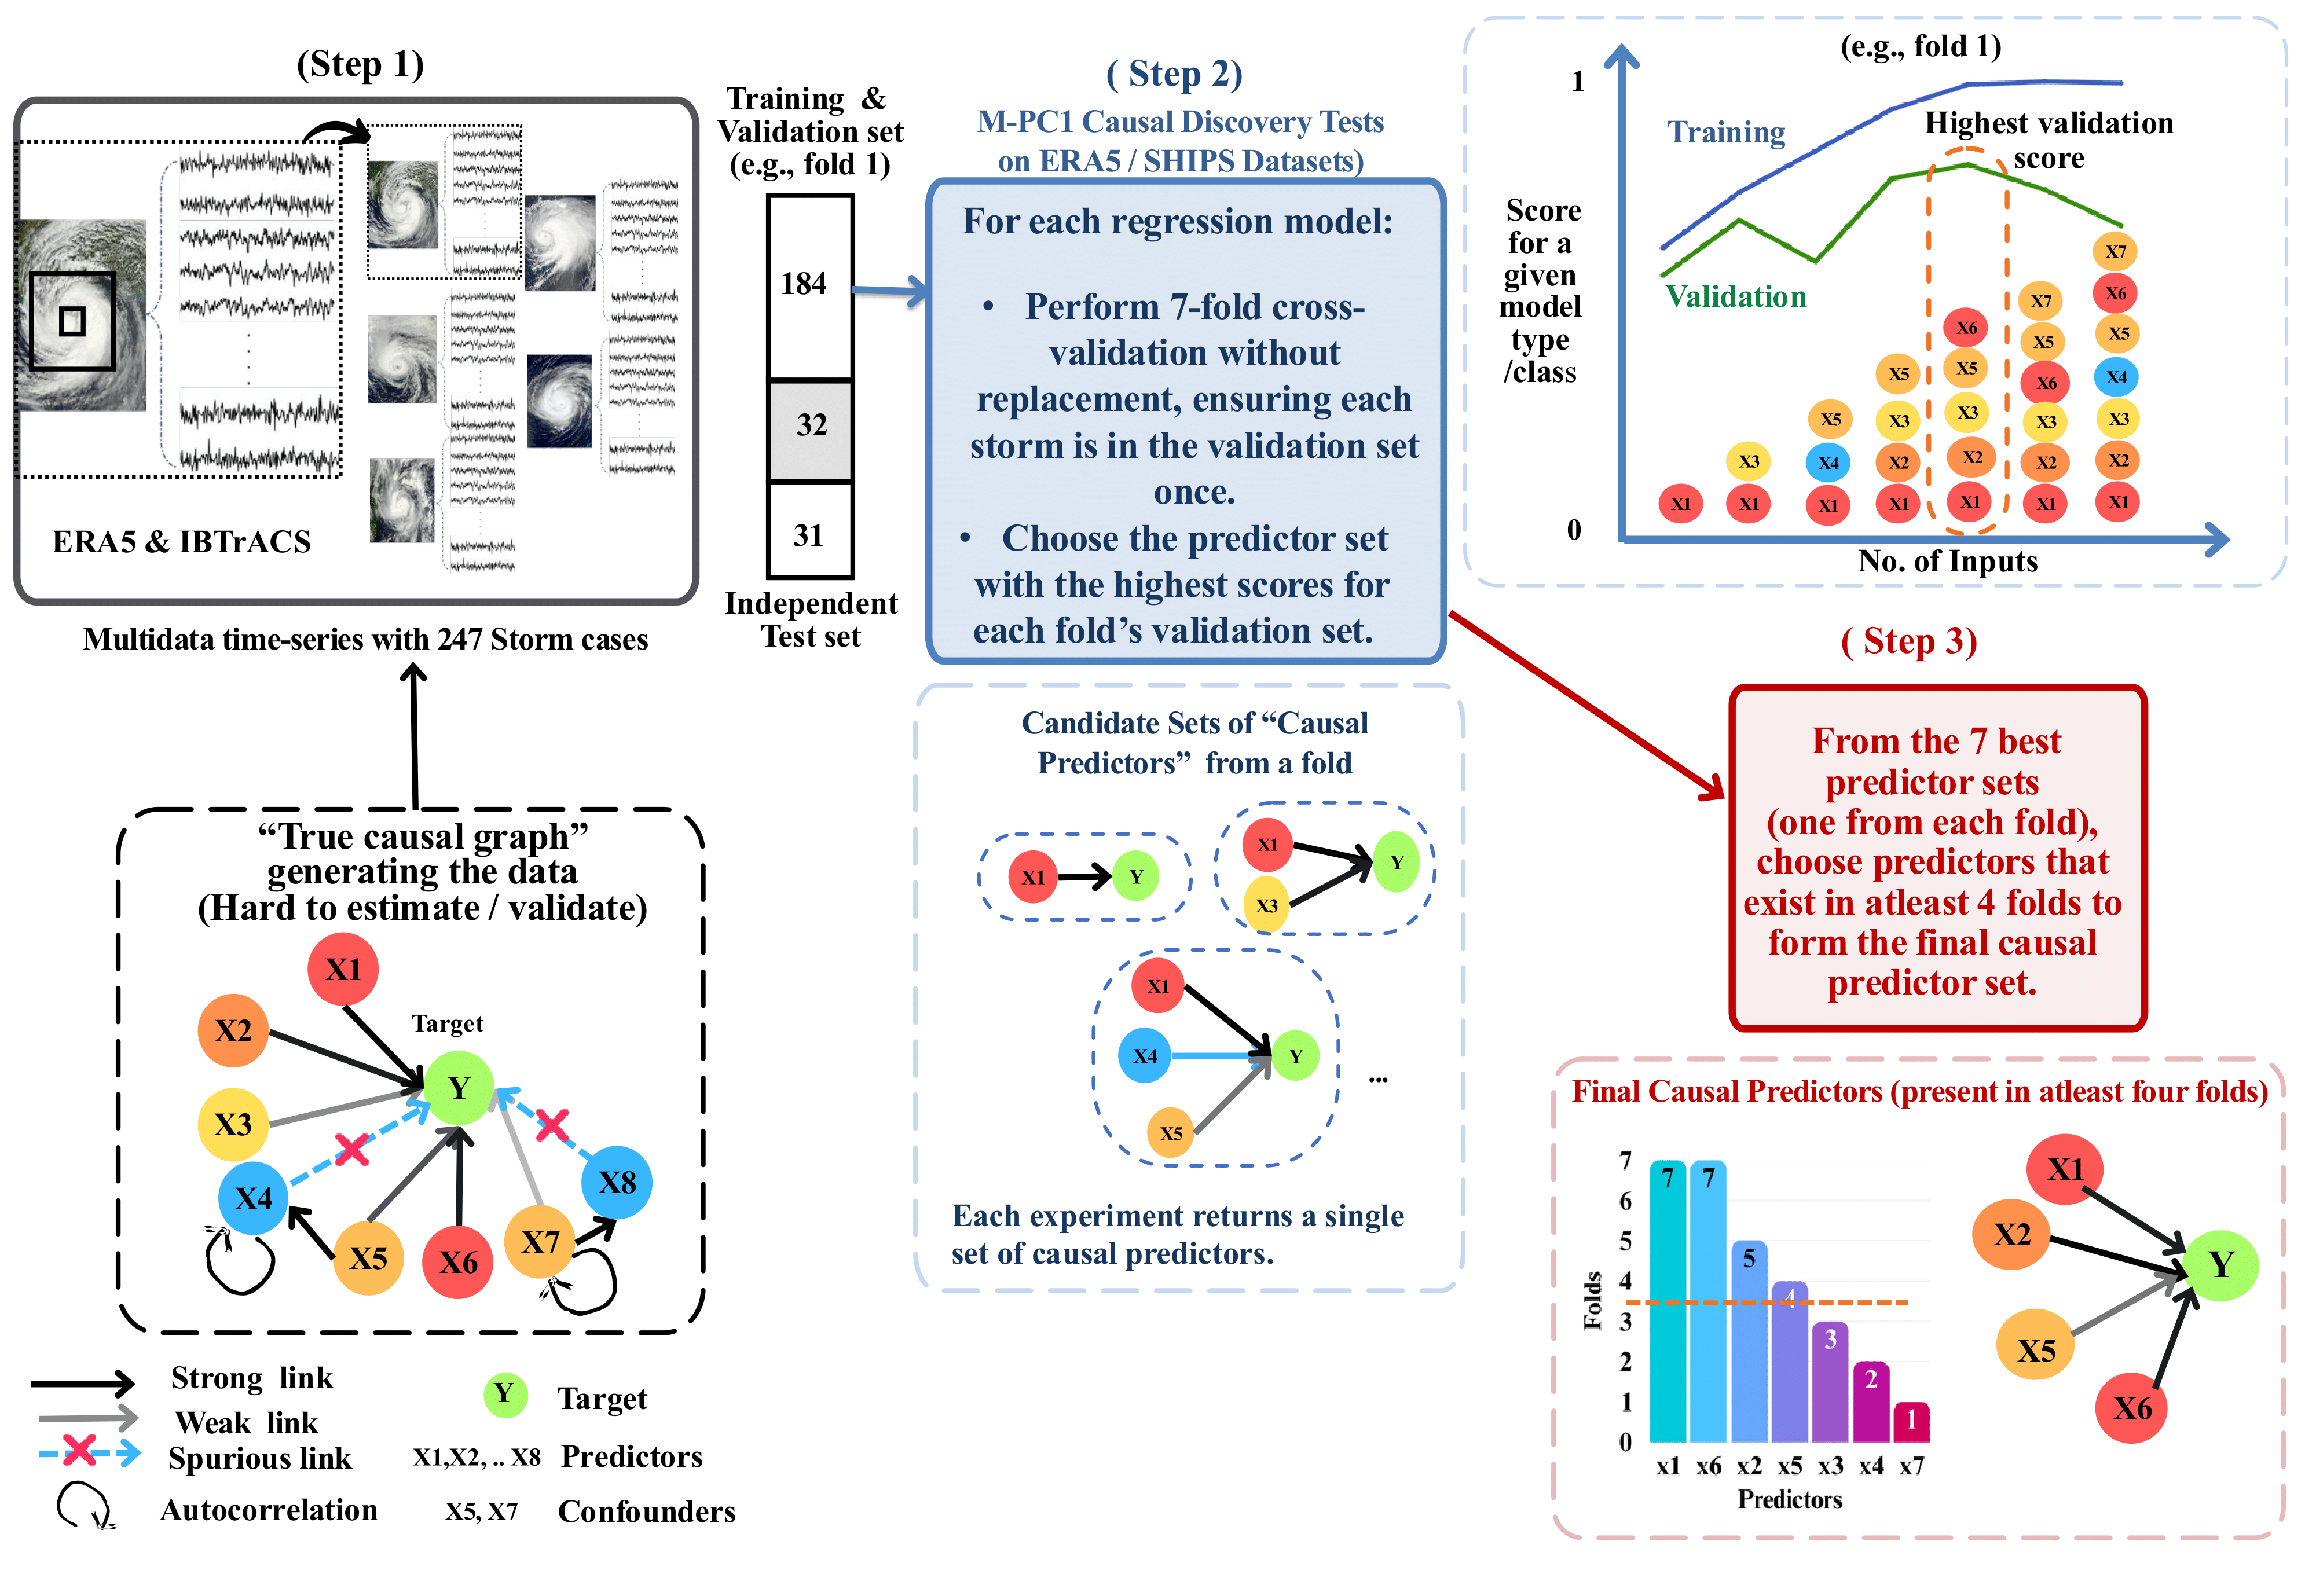


### Overview of the Causal Feature Selection Workflow

The figure summarises the full workflow described in the paper. In this tutorial, we focus on an example using the **prepared ERA5-based DELV24 dataset and fold 3**, rather than repeating the complete analysis across all seven folds.

1. **Prepare the data:** The dataset is aligned, multivariate time series for individual tropical cyclones using ERA5 predictors and IBTrACS storm information. Here, we use the already prepared dataset, which is divided into training, validation, and independent test sets.

2. **Discover candidate predictors:** M-PC applies conditional independence tests to identify candidate causal predictors. By varying `pc_alpha`, we explore how the selected predictors and forecasting performance change. In this tutorial, we examine one example fold and use a single-lag configuration appropriate for DELV24.

3. **Evaluate and select predictors:** In the full paper, the best-performing predictor set is identified for each fold, and selections are compared across folds to construct a more robust final set. Here, we explore the results for fold 3 to understand this process without running the complete seven-fold analysis.

4. **Interpret the results:** We compare forecasting performance with conventional feature-selection approaches and examine the contributions of selected predictors using SHAP. This helps us assess the potential value of causal feature selection and understand the behaviour of the fitted model.

---
### Reference
* **Primary Journal Article**: Ganesh, S. S., F. I.-H. Tam, M. S. Gomez, M. McGraw, M. DeMaria, K. Musgrave, J. Runge, and T. Beucler, 2026: *Multidata Causal Discovery for Statistical Hurricane Intensity Forecasting*. *Weather and Forecasting*, **41** (7), 1359–1375 [DOI: 10.1175/WAF-D-25-0208.1](https://doi.org/10.1175/WAF-D-25-0208.1)
* **Supplementary Information (SI)**: Ganesh et al. (2026): *Supplementary Information: Multidata Causal Discovery for Statistical Hurricane Intensity Forecasting*. *Weather and Forecasting* [DOI: 10.1175/WAF-D-25-0208.s1](https://doi.org/10.1175/WAF-D-25-0208.s1)
* **Code & Data Repository**: [GitHub (saranya8989/2025_CausalSHIPS)](https://github.com/saranya8989/2025_CausalSHIPS) | [Zenodo Archive (DOI: 10.5281/zenodo.17242382)](https://doi.org/10.5281/zenodo.17242382)
---

## Part I. Configuration and requirements

In this first step, we import the necessary scientific computing libraries and the core causal discovery framework, **Tigramite**, which provides the multi-dataset Peter–Clark (M-PC) implementation (*Runge, 2018; Ganesh et al., 2026*).

In [2]:
# Run this cell if executing in Google Colab
!pip install -q tigramite tqdm scikit-learn seaborn matplotlib pandas numpy scipy requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 314.7/314.7 kB 6.5 MB/s eta 0:00:00


In [3]:
# ==============================================================================
# Cell 1: Environment Setup & Dependencies
# ==============================================================================
import os
import gc
import glob
import zipfile
import sys
import pickle
import collections
from tqdm.auto import tqdm
import numpy as np
import pandas as pd
from scipy import stats

# Scikit-Learn Benchmarking
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score

# Tigramite Causal Discovery Framework
import tigramite
from tigramite.data_processing import DataFrame
from tigramite.independence_tests.parcorr import ParCorr
from tigramite.pcmci import PCMCI

# Visualization Setup
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("All dependencies successfully imported!")

All dependencies successfully imported!


### Repository and data setup

To ensure this notebook runs smoothly in cloud environments like Google Colab, we automatically synchronize the required data assets and scripts directly from the official **CausalSHIPS** GitHub repository (`saranya8989/2025_CausalSHIPS`).

This step clones the project directory and verifies the location of the preprocessed `data_for_tigramite` tensors required for the M-PC causal discovery workflow.

In [4]:
# ==============================================================================
# Cell 1B: Automated Repository Clone & Data Loading from GitHub
# ==============================================================================
import os

repo_name = "2025_CausalSHIPS"
repo_url = f"https://github.com/saranya8989/{repo_name}.git"

if not os.path.exists(repo_name):
    print(f"Cloning {repo_name} repository from GitHub...")
    !git clone -q {repo_url}
    print("Repository cloned successfully.")
else:
    print(f"Repository '{repo_name}' already exists locally.")

# Set working directory or ensure path alignment for Step 2
# This maps your data_for_tigramite folder instantly inside the Colab environment
data_path = os.path.join(repo_name, "data_for_tigramite")
if os.path.exists(data_path):
    print(f"Data directory verified at: {data_path}")
else:
    print("Warning: 'data_for_tigramite' folder not found in the root. Check repo folder structure.")

Cloning 2025_CausalSHIPS repository from GitHub...
Repository cloned successfully.
Data directory verified at: 2025_CausalSHIPS/data_for_tigramite


## Part II. Data ingestion and storm-level partitions

In this exercise, you will load a preprocessed fold, inspect its structure, identify the target and candidate predictors, and prepare storm-level data partitions for the forecasting experiments. The steps are separated into short cells so that you can see what each operation does.

- **Target predictand ($Y$):** 24-hour maximum surface wind-speed change, $\mathrm{DELV24}=\Delta V_{24}$ (kt).
- **Candidate predictors ($\mathbf{X}$):** atmospheric variables derived from ERA5 reanalysis and TC PRIMED. The supplied dataset is expected to contain 214 candidate predictors; verify this from the loaded file rather than assuming it.
- **Unit of partitioning:** the tropical cyclone storm, not an individual observation. All records belonging to one storm must remain in the same partition.

### Choosing a fold

The notebook defaults to Fold 3 to match the original analysis. You may select another available fold by changing `fold` in Q1. Use the same fold throughout the notebook: the M-PC sweep and saved-result lookup depend on this setting. Results from different folds should not be compared as though they came from the same held-out storms.

### How to work through this section

For each question, first try the fill-in-the-blanks cell. Hints and a **Possible solution** follow. The solution cells define the variables needed by later sections, so execute the solution after attempting the exercise (or use it directly if you are following the notebook as a worked example).

**Data-format note:** some prepared files contain a single storm dictionary that needs to be partitioned, while others already contain `train`, `valid`, and `test` storm dictionaries. The code below checks which structure is present. If partitions already exist in the file, it preserves them rather than splitting them a second time.

### Q1.1 — Select the fold and locate its data file

Choose a fold that is available in the repository. The filename convention is `tigramite_ready_dataset_delv24_<fold>.pkl`. The code also checks for a ZIP archive if the pickle has not yet been extracted.

**Your task:** set the fold number and build a search pattern for that fold.

💡 **Hints**
- Python f-strings let you insert a variable into a filename: [formatted string literals](https://docs.python.org/3/tutorial/inputoutput.html#formatted-string-literals).
- `glob.glob` returns a list of paths matching a pattern: [glob documentation](https://docs.python.org/3/library/glob.html).
- Keep `fold` consistent with the later M-PC and result-loading sections.

In [ ]:
# Complete the blanks; do not execute until you have filled them in.
fold = ___  # Choose an available fold, e.g. 3

target_dir = "2025_CausalSHIPS/data_for_tigramite"
os.makedirs(target_dir, exist_ok=True)

pkl_pattern = f"{target_dir}/tigramite_ready_dataset_delv24_{___}.pkl"
fold_pkls = glob.glob(pkl_pattern) or glob.glob(
    f"**/tigramite_ready_dataset_delv24_{___}.pkl", recursive=True
)
print("Fold:", fold)
print("Matching pickle files:", fold_pkls)

**Possible solution for Q1.1**

Fold 3 is the default used in the original analysis. If you choose another fold, confirm that its data file and corresponding saved M-PC results are available before running the later sections.

In [5]:
#@title Possible solution for Q1.1
fold = 3  # Change to another available fold if desired

target_dir = "2025_CausalSHIPS/data_for_tigramite"
os.makedirs(target_dir, exist_ok=True)
pkl_pattern = f"{target_dir}/tigramite_ready_dataset_delv24_{fold}.pkl"
fold_pkls = glob.glob(pkl_pattern) or glob.glob(
    f"**/tigramite_ready_dataset_delv24_{fold}.pkl", recursive=True
)

if not fold_pkls:
    zip_pattern = f"{target_dir}/tigramite_ready_dataset_delv24_{fold}.zip"
    zip_files = glob.glob(zip_pattern) or glob.glob(
        f"**/tigramite_ready_dataset_delv24_{fold}.zip", recursive=True
    )
    if zip_files:
        with zipfile.ZipFile(zip_files[0], "r") as zip_ref:
            zip_ref.extractall(target_dir)
        fold_pkls = glob.glob(pkl_pattern)

if not fold_pkls:
    raise FileNotFoundError(
        f"Could not find the pickle or ZIP archive for Fold {fold}. "
        "Check that the repository/data download completed and that this fold is available."
    )

target_pkl = fold_pkls[0]
print(f"Selected Fold {fold}: {target_pkl}")

Selected Fold 3: 2025_CausalSHIPS/data_for_tigramite/tigramite_ready_dataset_delv24_3.pkl


### Q1.2 — Load the file and inspect its structure

A pickle file stores a Python object. Before using it, load the object and inspect its top-level keys. This helps you understand what the file actually contains instead of assuming a particular data layout.

**Your task:** load the selected pickle and display its type and keys.

💡 **Hint:** use `pickle.load` with a file opened in binary-read mode (`"rb"`). See the [pickle documentation](https://docs.python.org/3/library/pickle.html). Only load pickle files from a trusted source.

In [ ]:
# Fill in the missing operations.
with open(target_pkl, ___) as f:
    fold_dict = pickle.___(f)

print("Loaded object type:", type(fold_dict))
print("Top-level keys:", list(fold_dict.___()))

**Possible solution for Q1.2**

Inspecting the keys is a useful diagnostic: the exact data layout determines whether the notebook should create a storm-level split or use partitions already supplied in the prepared file.

In [6]:
#@title Possible solution for Q1.2
with open(target_pkl, "rb") as f:
    fold_dict = pickle.load(f)

print("Loaded object type:", type(fold_dict))
print("Top-level keys:", list(fold_dict.keys()))

Loaded object type: <class 'dict'>
Top-level keys: ['Xnorml', 'trainmean', 'trainstd', 'var_names', 'aligned_train']


### Q1.3 — Identify the target and candidate predictors

The prepared data store the target first in the variable-name list, followed by the candidate predictors. Confirm this ordering from the file. Do not infer the target or the number of predictors from a hard-coded value alone.

**Your task:** extract `var_names`, `target_name`, and `feature_names`, then report how many candidate predictors are present.

💡 **Hint:** a Python list slice such as `items[1:]` selects all elements after the first. See [Python list operations](https://docs.python.org/3/tutorial/introduction.html#lists).

In [ ]:
## Complete the blanks; do not execute until you have filled them in.
var_names = list(fold_dict[___])
target_name = var_names[___]
feature_names = var_names[___:]

print("Target:", target_name)
print("Number of candidate predictors:", len(feature_names))
print("First five predictors:", feature_names[:5])

**Possible solution for Q1.3**

For this dataset, the target should correspond to DELV24 and the expected candidate predictor pool is 214 variables. If the loaded file reports something different, investigate the variable names and data version before proceeding.

In [7]:
#@title Possible solution for Q1.3
if "var_names" in fold_dict:
    var_names = list(fold_dict["var_names"])
else:
    # Some saved formats keep the names on a training DataFrame.
    xnorml = fold_dict.get("Xnorml", {})
    first_train = next(iter(xnorml.get("train", {}).values()), None)
    if first_train is None:
        raise KeyError("Could not find 'var_names' or a training DataFrame with column names.")
    var_names = list(first_train.columns)

target_name = var_names[0]
feature_names = var_names[1:]
print("Target:", target_name)
print("Number of candidate predictors:", len(feature_names))
print("First five predictors:", feature_names[:5])
if len(feature_names) != 214:
    print("Note: this file contains a different predictor count; verify the fold/data version.")

Target: delv24
Number of candidate predictors: 214
First five predictors: ['pmin', 'wind10', 'out_t250', 'out_t200', 'spdx']


### Q1.4 — Identify the storm-level data layout

Now determine whether the file contains a single dictionary of storms or already contains separate `train`, `valid`, and `test` dictionaries. This distinction matters: partitioning an already partitioned dataset a second time would change the intended experiment.

**Your task:** inspect the available keys and identify the representation used by this file.

💡 **Hints**
- The original workflow may store pooled storm records under `aligned_train` or `storm_dict`.
- The M-PC workflow expects `Xnorml` with `train`, `valid`, and `test` entries.
- See [Python dictionary methods](https://docs.python.org/3/library/stdtypes.html#dict).

In [ ]:
# Complete the blanks.
print("Has preprocessed aligned storms:", "aligned_train" in fold_dict)

print(
    "Has predefined train/valid/test splits:",
    "Xnorml" in fold_dict and all(
        part in fold_dict["Xnorml"]
        for part in [____, ____, ____]
    )
)

**Possible solution for Q1.4**

The solution below supports both layouts. If a pooled storm dictionary is available, it creates a reproducible 70/15/15 storm-level split. If the file already contains `Xnorml['train']`, `Xnorml['valid']`, and `Xnorml['test']`, it uses those supplied partitions and does not split them again.

In [9]:
# @title Possible solution for Q1.4

print("Has pooled aligned storms:", "aligned_train" in fold_dict)
print("Has storm_dict:", "storm_dict" in fold_dict)

# Check for predefined train/validation/test splits
xnorml = fold_dict.get("Xnorml", {})
has_splits = isinstance(xnorml, dict) and all(
    part in xnorml for part in ["train", "valid", "test"]
)

print("Has Xnorml splits:", has_splits)

# Inspect the contents of each split
if has_splits:
    for part in ["train", "valid", "test"]:
        print(f"\n{part.upper()} split:")
        print("Type:", type(xnorml[part]).__name__)

        if isinstance(xnorml[part], dict):
            print("Keys:", list(xnorml[part].keys()))
            print("Number of storms:", len(xnorml[part]))
        else:
            print("Shape:", getattr(xnorml[part], "shape", "Not available"))

Has pooled aligned storms: True
Has storm_dict: False
Has Xnorml splits: True

TRAIN split:
Type: dict
Keys: ['2018_KIRK', '2019_JERRY', '2012_ERNESTO', '2016_LISA', '2001_HUMBERTO', '2010_DANIELLE', '2017_RINA', '2006_ALBERTO', '2019_BARRY', '2012_HELENE', '2014_GONZALO', '2003_ANA', '2017_NATE', '2001_BARRY', '2005_RITA', '2016_JULIA', '2016_FIONA', '2001_LORENZO', '2013_MELISSA', '2005_PHILIPPE', '2017_IRMA', '2012_LESLIE', '2006_GORDON', '2002_DOLLY', '2009_BILL', '2012_SANDY', '2015_BILL', '2001_IRIS', '2004_DANIELLE', '2018_HELENE', '2009_IDA', '2005_CINDY', '2010_EARL', '2018_GORDON', '2011_LEE', '2011_KATIA', '2006_CHRIS', '2012_TONY', '2010_LISA', '2008_IKE', '2008_GUSTAV', '2017_GERT', '2010_JULIA', '2008_BERTHA', '2007_KAREN', '2008_FAY', '2012_CHRIS', '2019_GABRIELLE', '2007_FELIX', '2015_ANA', '2013_JERRY', '2003_ISABEL', '2002_FAY', '2016_ALEX', '2010_RICHARD', '2002_LILI', '2001_MICHELLE', '2005_DELTA', '2008_HANNA', '2005_IRENE', '2005_GAMMA', '2000_JOYCE', '2012_BERYL'

**Interpretation:** The file contains the preprocessed North Atlantic hurricane data in `aligned_train` and predefined `train`, `valid`, and `test` partitions in `Xnorml`. The partitions contain 184 training storms, 31 validation storms, and 31 test storms. Each split is a dictionary keyed by storm identifier (for example, `2018_KIRK` or `2005_WILMA`). These predefined partitions are used in the M-PC workflow and should not be split again.

### Q1.5 — Create or recover the storm-level partitions

If the data contain a pooled storm dictionary, assign whole storms to training (70%), validation (15%), and unseen test (the remainder). The pooled-dictionary branch preserves the original notebook’s deterministic split based on the stored storm order. If the file already contains partitions, retain those assignments. Do not change the splitting strategy without checking that it remains consistent with the saved M-PC results.

**Your task:** complete the split sizes and slices. Then check that the storm IDs do not overlap between partitions.

💡 **Hint:** Python slicing includes the start index and excludes the stop index. For slice boundaries, see [Python sequence operations](https://docs.python.org/3/library/stdtypes.html#common-sequence-operations).

In [ ]:
# Fill in the missing values/expressions.
if data_layout == "pooled_storm_dictionary":
    storm_ids = list(raw_storm_dict.keys())
    n_tr = int(___ * len(storm_ids))
    n_val = int(___ * len(storm_ids))
    train_keys = storm_ids[:___]
    val_keys = storm_ids[___:___]
    test_keys = storm_ids[___:]
else:
    # Use the partitions supplied in the prepared file.
    train_keys = list(fold_dict["Xnorml"]["train"].keys())
    val_keys = list(fold_dict["Xnorml"]["valid"].keys())
    test_keys = list(fold_dict["Xnorml"]["test"].keys())

assert set(train_keys).isdisjoint(val_keys)
assert set(train_keys).isdisjoint(test_keys)
assert set(val_keys).isdisjoint(test_keys)
print("Storm counts:", len(train_keys), len(val_keys), len(test_keys))

**Possible solution for Q1.5**

For a pooled storm dictionary, this reproduces the original deterministic 70/15/15 split based on stored storm order. For pre-partitioned files, the supplied split is preserved. Because the pooled branch depends on dictionary order, verify that this ordering matches the experimental design and the partitions used to generate saved M-PC results. This is important when saved M-PC results were produced using those same predefined partitions.

In [ ]:
#@title Possible solution for Q1.5
if data_layout == "pooled_storm_dictionary":
    storm_ids = list(raw_storm_dict.keys())
    n_tr = int(0.70 * len(storm_ids))
    n_val = int(0.15 * len(storm_ids))
    train_keys = storm_ids[:n_tr]
    val_keys = storm_ids[n_tr:n_tr + n_val]
    test_keys = storm_ids[n_tr + n_val:]
else:
    train_keys = list(fold_dict["Xnorml"]["train"].keys())
    val_keys = list(fold_dict["Xnorml"]["valid"].keys())
    test_keys = list(fold_dict["Xnorml"]["test"].keys())

assert set(train_keys).isdisjoint(val_keys)
assert set(train_keys).isdisjoint(test_keys)
assert set(val_keys).isdisjoint(test_keys)
print(f"Storm counts — train: {len(train_keys)}, validation: {len(val_keys)}, unseen test: {len(test_keys)}")

Storm counts — train: 128, validation: 27, unseen test: 29


### Q1.6 — Stack storm records and remove invalid rows

The forecasting models operate on arrays of samples, while the data are organized by storm. The next step stacks the records for the storms in each partition, separates the target column from the predictor columns, and removes rows with missing values.

**Your task:** complete the function so it returns `X` (predictors) and `y` (target). The function also supports files where the partitions are already supplied as dictionaries of storm DataFrames/arrays.

💡 **Hints**
- `np.vstack` stacks arrays vertically: [NumPy documentation](https://numpy.org/doc/stable/reference/generated/numpy.vstack.html).
- `np.isnan` identifies missing numeric values: [NumPy documentation](https://numpy.org/doc/stable/reference/generated/numpy.isnan.html).
- Check the column order before assuming that column 0 is the target.

In [ ]:
# Complete the blanks.
def stack_split(keys, storm_mapping):
    stacked = np.vstack([
        storm_mapping[k].values if hasattr(storm_mapping[k], "values")
        else np.asarray(storm_mapping[k])
        for k in keys
    ])
    y = stacked[:, ___]
    X = stacked[:, ___:]
    valid_mask = ~np.isnan(X).any(axis=1) & ~np.isnan(y)
    return X[valid_mask], y[valid_mask]

**Possible solution for Q1.6**

For pooled storm data, apply `stack_split` to the pooled dictionary. For pre-partitioned data, stack each split separately. The original `Xnorml` representation may use a sentinel value such as `-999` for missing data in the M-PC workflow; this cell specifically filters `NaN` values in the data used for the downstream scikit-learn benchmarks. Do not silently treat a sentinel as a NaN.

In [ ]:
#@title Possible solution for Q1.6

def stack_split(keys, storm_mapping):
    stacked = np.vstack([
        storm_mapping[k].values if hasattr(storm_mapping[k], "values")
        else np.asarray(storm_mapping[k])
        for k in keys
    ])
    y = stacked[:, 0]
    X = stacked[:, 1:]
    valid_mask = ~np.isnan(X).any(axis=1) & ~np.isnan(y)
    return X[valid_mask], y[valid_mask]

if data_layout == "pooled_storm_dictionary":
    X_tr, y_tr = stack_split(train_keys, raw_storm_dict)
    X_val, y_val = stack_split(val_keys, raw_storm_dict)
    X_te, y_te = stack_split(test_keys, raw_storm_dict)
    test_dict = {k: raw_storm_dict[k] for k in test_keys}
else:
    # Use the already-defined storm partitions in Xnorml.
    train_dict = fold_dict["Xnorml"]["train"]
    val_dict = fold_dict["Xnorml"]["valid"]
    test_dict = fold_dict["Xnorml"]["test"]
    X_tr, y_tr = stack_split(train_keys, train_dict)
    X_val, y_val = stack_split(val_keys, val_dict)
    X_te, y_te = stack_split(test_keys, test_dict)

print("X_tr:", X_tr.shape, "y_tr:", y_tr.shape)
print("X_val:", X_val.shape, "y_val:", y_val.shape)
print("X_te:", X_te.shape, "y_te:", y_te.shape)

X_tr: (4179, 214) y_tr: (4179,)
X_val: (944, 214) y_val: (944,)
X_te: (1039, 214) y_te: (1039,)


### Q1.7 — Verify the dataset before continuing

Before running causal discovery, check the target name, predictor count, sample counts, and storm counts. Also confirm that no storm appears in more than one partition.

**Think about it:** why is a storm-level split more appropriate than randomly splitting individual time steps from the same storm? What kind of overly optimistic evaluation could result from leakage across partitions?

In [ ]:
#fill in the missing values
print("=" * 72)
print(f"DATASET LOADED: {os.path.basename(_____)}")
print("Fold:", _______)
print("Data layout:", ___________)
print("Target predictand:", ____________)
print("Candidate predictors:", len(__________))
print(f"Training samples:   {X_tr.shape[0]} ({len(train_keys)} storms)")
print(f"Validation samples: {X_val.shape[0]} ({len(val_keys)} storms)")
print(f"Unseen test samples:{X_te.shape[0]} ({len(test_keys)} storms)")
print("Storm partitions are mutually exclusive:",
      set(train_keys).isdisjoint(val_keys)
      and set(train_keys).isdisjoint(test_keys)
      and set(val_keys).isdisjoint(test_keys))
print("=" * 72)
assert X_tr.shape[1] == len(__________), (
    f"Predictor mismatch: X has {X_tr.shape[1]} columns but {len(_______)} names were found."
)

In [ ]:
#@title Possible solution for Q1.7
print("=" * 72)
print(f"DATASET LOADED: {os.path.basename(target_pkl)}")
print("Fold:", fold)
print("Data layout:", data_layout)
print("Target predictand:", target_name)
print("Candidate predictors:", len(feature_names))
print(f"Training samples:   {X_tr.shape[0]} ({len(train_keys)} storms)")
print(f"Validation samples: {X_val.shape[0]} ({len(val_keys)} storms)")
print(f"Unseen test samples:{X_te.shape[0]} ({len(test_keys)} storms)")
print("Storm partitions are mutually exclusive:",
      set(train_keys).isdisjoint(val_keys)
      and set(train_keys).isdisjoint(test_keys)
      and set(val_keys).isdisjoint(test_keys))
print("=" * 72)
assert X_tr.shape[1] == len(feature_names), (
    f"Predictor mismatch: X has {X_tr.shape[1]} columns but {len(feature_names)} names were found."
)

DATASET LOADED: tigramite_ready_dataset_delv24_3.pkl
Fold: 3
Data layout: pooled_storm_dictionary
Target predictand: delv24
Candidate predictors: 214
Training samples:   4179 (128 storms)
Validation samples: 944 (27 storms)
Unseen test samples:1039 (29 storms)
Storm partitions are mutually exclusive: True


---

## Part III. Explore and run M-PC causal discovery

The aim is **causal feature selection for forecasting**, not reconstruction of every edge in a complete atmospheric causal graph. Before running the full significance sweep, inspect the prepared multi-storm data, examine the expert-defined link assumptions, and run a small diagnostic configuration. The full alpha sweep is deliberately kept in a separate solution cell because it can be computationally expensive.

**Important:** The main experiment uses target index `0`, `ParCorr`, and `causal_settings.link_shipsera5` assumptions at the single requested lag `4`. Keep these settings fixed for the reported sweep unless a question explicitly asks you to test an alternative. The custom `train_PC1.Pipeline` uses `missing_flag=-999.0`; the prepared arrays must use the same sentinel.


### Q2.1 — Explore the data before modelling

Do not treat the pickle as a black box. Inspect the variable names, the number of storms in each split, the number of time steps available for a few storms, and the distribution of the target (`DELV24`).

**Explore:**
1. Which variable is the target, and how many candidate predictors are available?
2. Do storm records have the same number of time steps?
3. What do the target histogram and one storm's target trajectory suggest about the data?
4. Why should storms remain separate time series rather than being concatenated into one artificial sequence?

Use the next cell as a starting point; add your own summaries or plots before opening the example solution.

In [ ]:
# Causal-discovery setup: load the selected fold and custom model code.

models_dir = os.path.abspath("2025_CausalSHIPS/util/models")
if models_dir not in sys.path:
    sys.path.append(models_dir)

import causal_settings
import train_PC1

# Reuse the fold selected in Part II.
data_path = target_pkl
print(f"Loading prepared fold {fold}: {data_path}")
with open(data_path, "rb") as f:
    TIDATA = pickle.load(f)

first_key = next(iter(TIDATA["Xnorml"]["train"]))
var_names = list(TIDATA["Xnorml"]["train"][first_key].columns)
target_name = var_names[0]
feature_names = var_names[1:]
print(f"Target: {target_name}; candidate predictors: {len(feature_names)}")
print("Storms by split:", {part: len(TIDATA["Xnorml"][part]) for part in ("train", "valid", "test")})


Loading prepared fold 3: 2025_CausalSHIPS/data_for_tigramite/tigramite_ready_dataset_delv24_3.pkl
Target: delv24; candidate predictors: 214
Storms by split: {'train': 184, 'valid': 31, 'test': 31}


In [ ]:
# Explore the data — add or modify these diagnostics.
print("First 12 variables:", var_names[:12])
print("\nFirst training storm key:", first_key)
first_storm = TIDATA["Xnorml"]["train"][first_key]
display(first_storm.head())
print("Storm shape:", first_storm.shape)
print("Missing values in first storm (top 10 columns):")
display(first_storm.isna().sum().sort_values(ascending=False).head(10))
print("\nTarget summary across the first training storm:")
display(first_storm[target_name].describe())


First 12 variables: ['delv24', 'pmin', 'wind10', 'out_t250', 'out_t200', 'spdx', 'out_mean_midrhum', 'POT', 'POT2', 'PER', 'VPER', 'SHDC']

First training storm key: 2018_KIRK


,delv24,pmin,wind10,out_t250,out_t200,spdx,out_mean_midrhum,POT,POT2,PER,...,tanom100,tanom150,tanom200,tanom250,tanom300,tanom400,tanom500,tanom700,tanom850,tanom1000
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Storm shape: (83, 215)
Missing values in first storm (top 10 columns):


,0
delv24,63
pmin,63
wind10,63
out_t250,63
out_t200,63
spdx,63
out_mean_midrhum,63
POT,63
POT2,63
PER,63



Target summary across the first training storm:


,delv24
count,20.000000
mean,0.938245
std,1.925369
min,-2.934040
25%,0.033099
50%,0.977764
75%,2.103648
max,4.343287


### Understanding the Missing Values

Storms are aligned in time relative to their minimum central pressure to satisfy the stationarity assumption before applying causal discovery algorithms. Since storms have different durations, shorter storms are padded with `NaN` values at either end to maintain a consistent temporal alignment. Consequently, the first few rows may contain mostly missing values.

To inspect the actual observations, we display a window around the middle of the observed section. This is for visualization only; the original alignment and missing values are preserved for subsequent analysis.

In [ ]:

# Identify rows containing at least one actual observation
nonempty_positions = np.flatnonzero(first_storm.notna().any(axis=1))

if len(nonempty_positions) == 0:
    print("This storm contains no non-missing observations.")
else:
    # Display a window around the middle of the observed section
    middle_pos = nonempty_positions[len(nonempty_positions) // 2]
    half_window = 5

    start = max(0, middle_pos - half_window)
    end = min(len(first_storm), middle_pos + half_window + 1)

    print(
        f"\nRows {start}–{end - 1}, around the middle of the "
        "observed section:"
    )
    display(first_storm.iloc[start:end])

    print(
        f"\nRows containing at least one observation: "
        f"{len(nonempty_positions)} / {len(first_storm)}"
    )

    # Examine target availability separately
    if target_name in first_storm.columns:
        target_valid = np.flatnonzero(
            first_storm[target_name].notna().to_numpy()
        )

        print(f"\nValid {target_name} observations: {len(target_valid)}")

        if len(target_valid):
            print(
                f"Target-valid row range: "
                f"{target_valid[0]}–{target_valid[-1]}"
            )


Rows 68–78, around the middle of the observed section:


,delv24,pmin,wind10,out_t250,out_t200,spdx,out_mean_midrhum,POT,POT2,PER,...,tanom100,tanom150,tanom200,tanom250,tanom300,tanom400,tanom500,tanom700,tanom850,tanom1000
68,1.483514,0.799197,-0.625845,0.474885,0.118034,2.381520,0.889941,0.558109,0.543015,0.229631,...,0.142331,-0.560325,-0.738895,-0.632293,-0.509955,-0.712366,-0.937799,-1.027214,-1.046260,-0.922841
69,0.533345,0.609124,-0.392343,0.351311,-0.124378,2.041899,0.761047,0.672577,0.717396,0.337739,...,0.058899,-0.530827,-0.507623,-0.775439,-0.692817,-0.796351,-0.878260,-0.966561,-1.087838,-0.786128
70,0.951015,0.784803,-0.229383,0.354974,-0.089297,1.993123,0.558800,0.574314,0.567346,0.480115,...,0.415748,-0.452506,-0.725849,-0.810475,-0.910845,-0.851198,-0.774517,-0.861886,-0.962037,-0.758341
71,1.477856,0.628722,-0.512737,0.418376,0.020321,1.990115,0.652299,0.603677,0.611732,-0.201070,...,0.196612,-0.626440,-0.813614,-0.587247,-0.446657,-0.337864,-0.494861,-0.977322,-1.177391,-0.993975
72,0.633537,0.756297,-0.377677,0.372742,-0.134801,2.011263,0.650683,0.604424,0.612866,-0.237841,...,-0.461799,-0.254161,-0.721105,-0.615276,-0.601386,-0.547825,-0.456070,-0.667210,-1.011078,-1.115127
73,-0.144146,0.526653,-0.303123,0.360173,-0.252145,1.897711,0.503873,0.839256,0.981783,0.233861,...,-0.267794,-0.383340,-0.528972,-0.558218,-0.557429,-0.517831,-0.520121,-0.703406,-0.947112,-1.145137
74,-2.088552,0.663558,-0.070293,0.401002,-0.212970,1.580383,0.512163,0.598564,0.603975,0.362715,...,-0.421591,-0.370117,-0.399696,-0.473131,-0.378084,-0.481837,-0.603115,-0.705362,-0.954575,-1.248505
75,0.092181,0.525200,-0.265515,0.486499,-0.044936,1.375885,0.548196,0.637973,0.664063,0.007166,...,-0.448731,-0.299933,-0.335652,-0.285940,-0.292807,-0.579534,-0.604017,-0.543947,-0.647535,-0.882827
76,2.867579,0.586385,-0.271696,0.508738,-0.026364,1.373387,0.470158,0.562564,0.549693,-0.307835,...,-0.042627,-0.476918,-0.270421,-0.352007,-0.542484,-0.702940,-0.624766,-0.478403,-0.580371,-0.534933
77,2.958088,0.505649,-0.327236,0.375867,-0.237986,1.261637,0.495850,0.609947,0.621260,-0.123742,...,-0.593481,-0.331465,-0.096077,-0.451108,-0.671718,-0.931755,-0.633787,-0.401120,-0.495082,-0.414893



Rows containing at least one observation: 20 / 83

Valid delv24 observations: 20
Target-valid row range: 63–82


**Example solution / one possible exploration**

The code below plots the target distribution for one training storm and its time evolution. Explore additional storms too: a single storm is not necessarily representative of the whole dataset.

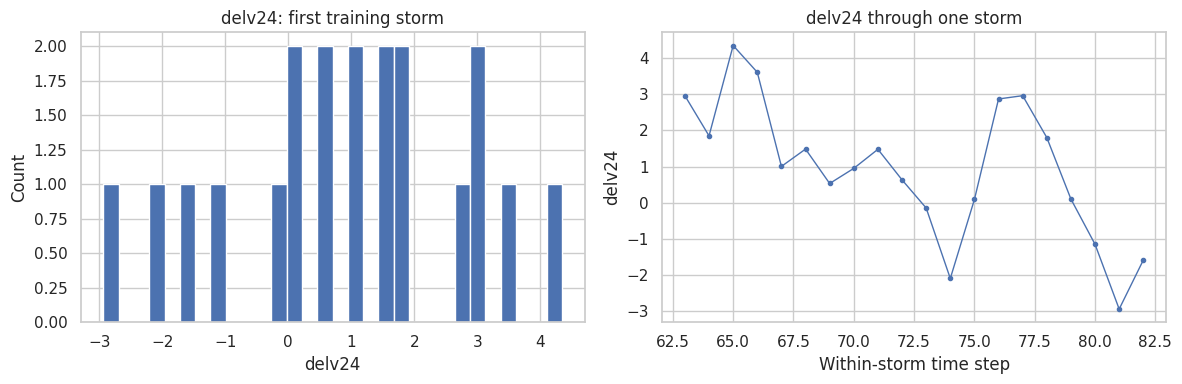

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
first_storm[target_name].dropna().hist(bins=30, ax=axes[0])
axes[0].set_title(f"{target_name}: first training storm")
axes[0].set_xlabel(target_name)
axes[0].set_ylabel("Count")
axes[1].plot(first_storm[target_name].to_numpy(), marker=".", linewidth=1)
axes[1].set_title(f"{target_name} through one storm")
axes[1].set_xlabel("Within-storm time step")
axes[1].set_ylabel(target_name)
plt.tight_layout()
plt.show()


### Q2.2 — Exploring Causal Settings and Link Assumptions

Causal discovery depends not only on the data and statistical thresholds but also on our assumptions about possible relationships between variables.

In the paper, we investigate different configurations for selecting tropical cyclone intensity predictors. These include retaining existing SHIPS predictors while searching for additional ERA5-based predictors, and allowing the algorithm to examine the available predictors more freely.

In this tutorial, we explore three configurations defined in the `causal_settings` module:

1. **SHIPS-only, without additional ERA5 predictors:** Uses the SHIPS variables to identify candidate predictors of intensity change, without adding the broader ERA5 predictor set.
2. **SHIPS + ERA5, with link assumptions:** Prescribes existing SHIPS links while allowing additional ERA5 predictors to be investigated.
3. **SHIPS + ERA5, without link assumptions:** Allows the algorithm to evaluate the available predictors without prescribing the same SHIPS links.



In [ ]:
# Inspect the causal-setting functions available in this module.
print([name for name in dir(causal_settings) if name.startswith("link_")])

# Display the implementation of each function to explore its assumptions.
import inspect

for name in [
    "link_onlyships",
    "link_shipsera5_withassum",
    "link_shipsera5",
]:
    function = getattr(causal_settings, name)
    print(f"\n--- {name} ---")
    print(inspect.getsource(function))

['link_onlyships', 'link_shipsera5', 'link_shipsera5_withassum']

--- link_onlyships ---
def link_onlyships(numvar=None,lag=None,target_ind=None):
    # Creating the causal arrows towards the target
    ships_index = np.arange(0,numvar)
    super_dict = collections.defaultdict(list)
    for d in [{(obj,-lag):"-?>"} for obj in ships_index]:
        for k, v in d.items():
            super_dict[k].append(str(v))
    tdict = dict(super_dict)
    
    # Assign causal settings to each target
    result = {key:str(value[0]) for key,value in tdict.items()}
    ships_links= {obj:result for obj in target_ind}
    for vartargetindex in target_ind:
        ships_links[vartargetindex].update({(var, -lagz): '-?>' for var in list(np.arange(0,numvar)) for lagz in range(lag,lag+1)})
        
    empty_list = {}
    for vartargetindex in range(target_ind[-1]+1,numvar):
        empty_list[vartargetindex] = {}
    all_links = ships_links.copy()
    all_links.update(empty_list)
    return all_links


--- 

### Understanding Link Assumptions in Tigramite

Tigramite allows us to incorporate prior knowledge about possible causal relationships through `link_assumptions`. The symbols specify which links are prescribed and which remain candidates for discovery:

- **`-->` — Assumed link:** The link is specified as existing in the assumed direction. M-PC does not test whether to remove it.
- **`-?>` — Possible link:** The link may or may not exist, but its direction is specified if it does. M-PC uses conditional independence tests to assess candidate links during the discovery process.
- **Link not specified:** When an explicit `link_assumptions` dictionary is provided, omitted links are assumed absent.

In our SHIPS + ERA5 configuration with link assumptions, existing SHIPS links are retained while additional ERA5 predictors are investigated as possible links. Without these assumptions, the algorithm has greater freedom to select or exclude available predictors.


In [ ]:
# Explore the causal settings — compare link-assumption objects without running M-PC yet.
numvar = len(var_names)
links_lag2 = causal_settings.link_shipsera5(numvar=numvar, lag=2, target_ind=[0])
links_lag4 = causal_settings.link_shipsera5(numvar=numvar, lag=4, target_ind=[0])

print("Variables supplied:", numvar)
print("lag=2 assumptions type:", type(links_lag2).__name__)
print("lag=4 assumptions type:", type(links_lag4).__name__)
print("lag=2 summary:", repr(links_lag2)[:1200])
print("lag=4 summary:", repr(links_lag4)[:1200])


Variables supplied: 215
lag=2 assumptions type: dict
lag=4 assumptions type: dict
lag=2 summary: {0: {(np.int64(0), -2): '-?>', (np.int64(1), -2): '-?>', (np.int64(2), -2): '-?>', (np.int64(3), -2): '-?>', (np.int64(4), -2): '-?>', (np.int64(5), -2): '-?>', (np.int64(6), -2): '-?>', (np.int64(7), -2): '-?>', (np.int64(8), -2): '-?>', (np.int64(9), -2): '-?>', (np.int64(10), -2): '-?>', (np.int64(11), -2): '-?>', (np.int64(12), -2): '-?>', (np.int64(13), -2): '-?>', (np.int64(14), -2): '-?>', (np.int64(15), -2): '-?>', (np.int64(16), -2): '-?>', (np.int64(17), -2): '-?>', (np.int64(18), -2): '-?>', (np.int64(19), -2): '-?>', (np.int64(20), -2): '-?>', (np.int64(21), -2): '-?>', (np.int64(22), -2): '-?>', (np.int64(23), -2): '-?>', (np.int64(24), -2): '-?>', (np.int64(25), -2): '-?>', (np.int64(26), -2): '-?>', (np.int64(27), -2): '-?>', (np.int64(28), -2): '-?>', (np.int64(29), -2): '-?>', (np.int64(30), -2): '-?>', (np.int64(31), -2): '-?>', (np.int64(32), -2): '-?>', (np.int64(33), -2



**Go further:** Try another causal-setting function and inspect its returned link assumptions. Consider how changing the configuration alters the relationships M-PC can investigate. Before running a new experiment, ensure that the variable indices, target index, and lag settings match the prepared dataset.

**Key point:** Link assumptions define the search space for causal discovery. Prescribing a link is not the same as discovering it from the data, and allowing a link as a candidate does not guarantee that M-PC will retain it.

### Possible Solution / Interpretation

The function takes the number of variables, the lag, and the target index, then returns the link-assumption structure expected by the custom M-PC pipeline.

In the supplied implementation, `link_shipsera5` constructs candidate links at exactly `-lag`, using `range(lag, lag + 1)`. It therefore specifies a **single lag**, rather than a range of lags. For example, `lag=2` and `lag=4` define different single-lag experiments.

To match these assumptions, set `tau_min0=tau_max0=lag` in the main M-PC run. PC-Stable does not inherently require equal minimum and maximum lag bounds; this setting matches the single-lag configuration used in this tutorial.

Remember that causal discovery identifies candidate relationships under the chosen assumptions and statistical tests. Predictive correlation alone does not establish causal direction.

### Q2.3 — Run one diagnostic model before the full sweep

A full sweep evaluates many `pc_alpha` values and can take time. First run **one** configuration and inspect the selected parents of the target. Then, if runtime permits, change one setting at a time (for example `pilot_alpha` or `pilot_lag`) and compare the result.

**Questions**
1. What changes when `pc_alpha` changes? What stays fixed in this diagnostic run?
2. Does the target's selected parent set change when you alter the significance threshold or lag assumptions?
3. Why should a change in the discovered graph be reported even if it does not improve downstream forecast skill?
4. Why is this pilot not a replacement for the systematic sweep?

**Note:** This cell runs M-PC once and may take several minutes. Change only one setting per comparison and record the setting used.

In [ ]:
# Prepare the multi-storm dictionaries once; share them between the pilot and full sweep.
# IMPORTANT: train_PC1.Pipeline hard-codes missing_flag=-999.0 when it builds
# the Tigramite DataFrame. Use the same sentinel here; 999.0 would be treated
# as a real observation by that custom pipeline.
MISSING_FLAG = -999.0
Xnorml_c = {}
for part in ("train", "valid", "test"):
    Xnorml_c[part] = {}
    for i, key in enumerate(TIDATA["Xnorml"][part].keys()):
        arr = TIDATA["Xnorml"][part][key].to_numpy(dtype=float, copy=True)
        arr[~np.isfinite(arr)] = MISSING_FLAG
        Xnorml_c[part][i] = arr

# Tigramite converts sentinel values to NaN inside DataFrame construction. The
# repository Pipeline makes only a shallow dictionary copy, so pass fresh arrays
# to every run to avoid mutating this reusable prepared data between alpha values.
def fresh_storm_dict(part):
    return {key: arr.copy() for key, arr in Xnorml_c[part].items()}

print("Prepared storm counts:", {part: len(Xnorml_c[part]) for part in Xnorml_c})
print("Example training array shape:", next(iter(Xnorml_c["train"].values())).shape)
for part, storms in Xnorml_c.items():
    remaining_nonfinite = sum((~np.isfinite(arr)).sum() for arr in storms.values())
    sentinel_count = sum((arr == MISSING_FLAG).sum() for arr in storms.values())
    print(f"{part}: remaining non-finite={remaining_nonfinite}; sentinel (-999.0) values={sentinel_count}")
    assert remaining_nonfinite == 0, f"Non-finite values remain in {part}."


Prepared storm counts: {'train': 184, 'valid': 31, 'test': 31}
Example training array shape: (83, 215)
train: remaining non-finite=0; sentinel (-999.0) values=2371665
valid: remaining non-finite=0; sentinel (-999.0) values=244670
test: remaining non-finite=0; sentinel (-999.0) values=211345


In [ ]:
# Diagnostic run — edit one parameter at a time, then compare outputs.
pilot_alpha = 0.05
pilot_lag = 2  # Try 2, then 4; link_shipsera5 permits links at this lag only.
pilot_links = causal_settings.link_shipsera5(
    numvar=len(var_names), lag=pilot_lag, target_ind=[0]
)

pilot_pipeline = train_PC1.Pipeline(
    data=fresh_storm_dict("train"),
    pc_alpha=pilot_alpha,
    pc_type="run_pcstable",
    tau_min0=pilot_lag,  # test the single lag permitted by pilot_links
    tau_max0=pilot_lag,
    var_name=var_names,
    cond_ind_test=ParCorr(significance="analytic"),
    link_assumptions=pilot_links
)
pilot_result = pilot_pipeline.run_tigramite()
print("Pilot alpha:", pilot_alpha, "| tested lag:", pilot_lag)
print("Target-parent entries:", pilot_result.get(0, []))


Pilot alpha: 0.05 | tested lag: 2
Target-parent entries: [(np.int64(0), -2), (np.int64(17), -2), (np.int64(2), -2), (np.int64(123), -2), (np.int64(145), -2), (np.int64(144), -2), (np.int64(16), -2), (np.int64(155), -2), (np.int64(148), -2)]


### Question: Which predictors does M-PC identify as potential causes of the target for this pilot run?
1. How many distinct predictors are selected?
2. What does the lag value of −2 mean when the data are sampled every six hours?
3. Why might changing pilot_alpha or pilot_lag change the selected predictors?
4. Does a variable selected by M-PC necessarily improve intensity-forecast performance?

Important interpretation: A lag of −2 represents a variable two time steps in the past—12 hours earlier for six-hourly data. The selected links indicate conditional dependencies under the specified causal-discovery assumptions; they should not automatically be interpreted as proof of physical causation

In [ ]:
# Map the selected target parents to variable names

target_parents = pilot_result.get(0, [])

print(f"Target: {var_names[0]}")
print(f"Pilot alpha: {pilot_alpha} | Pilot lag: {pilot_lag}")
print("\nSelected target parents:")
print("-" * 75)

for var_idx, lag_val in target_parents:
    var_idx = int(var_idx)
    print(
        f"Variable index: {var_idx:3d} | "
        f"Variable name: {var_names[var_idx]:30s} | "
        f"Lag: {lag_val}"
    )

Target: delv24
Pilot alpha: 0.05 | Pilot lag: 2

Selected target parents:
---------------------------------------------------------------------------
Variable index:   0 | Variable name: delv24                         | Lag: -2
Variable index:  17 | Variable name: sdir                           | Lag: -2
Variable index:   2 | Variable name: wind10                         | Lag: -2
Variable index: 123 | Variable name: outrhum_1000                   | Lag: -2
Variable index: 145 | Variable name: shear_1000_700                 | Lag: -2
Variable index: 144 | Variable name: shear_1000_500                 | Lag: -2
Variable index:  16 | Variable name: tadv                           | Lag: -2
Variable index: 155 | Variable name: shear_850_250.1                | Lag: -2
Variable index: 148 | Variable name: shear_850_300                  | Lag: -2


### Full-run solution — M-PC significance alpha sweep

After attempting the exploration above, run this section to reproduce the main configuration. The main sweep restores `lag = 4` following the paper as the target is Delv24. It reuses the prepared storm dictionaries instead of rebuilding them inside every iteration. The validation/test partitions are retained in the saved package, while M-PC discovery itself uses the training storms.

In [ ]:
# Main experiment settings (kept separate from the pilot settings).
lag = 4
onlyships_lag = causal_settings.link_shipsera5(
    numvar=len(var_names), lag=lag, target_ind=[0]
)
pc_alpha_grid = [
    0.001, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06,
    0.07, 0.08, 0.09, 0.1, 0.2,0.3,0.4, 0.5, 0.6, 0.7, 0.8, 0.9
]
print(f"Fold {fold}; target={target_name}; tested lag={lag}; {len(pc_alpha_grid)} alpha settings")
print("Link assumptions type:", type(onlyships_lag).__name__)


Fold 3; target=delv24; tested lag=4; 19 alpha settings
Link assumptions type: dict


In [ ]:
# Run the full M-PC alpha sweep. This is the computationally intensive step.
# link_shipsera5() defines target links only at -lag, so use tau_min0=tau_max0=lag.
# PC-Stable does not require equal bounds generally; this follows this experiment's link assumptions.
results = []
for pc_alpha in tqdm(pc_alpha_grid, desc=f"M-PC Sweep (Fold {fold})"):
    pipeline_run = train_PC1.Pipeline(
        data=fresh_storm_dict("train"),
        pc_alpha=pc_alpha,
        pc_type="run_pcstable",
        tau_min0=lag,
        tau_max0=lag,
        var_name=var_names,
        cond_ind_test=ParCorr(significance="analytic"),
        link_assumptions=onlyships_lag
    )
    results.append(pipeline_run.run_tigramite())
    gc.collect()

assert len(results) == len(pc_alpha_grid), "Some alpha configurations did not return a result."
print(f"Completed {len(results)} M-PC runs.")


M-PC Sweep (Fold 3):   0%|          | 0/19 [00:00<?, ?it/s]

Completed 19 M-PC runs.


In [ ]:
# Save the discovery results for the downstream evaluation sections.
saveto = {
    "dataframes": TIDATA["Xnorml"],
    "PC1_results": results,
    "var_names": var_names,
    "pc_alpha_grid": pc_alpha_grid,
    "lag": lag,
    "fold": fold
}
out_dir = f"results/{lag}/SHIPSERA5_linkassum/"
os.makedirs(out_dir, exist_ok=True)
out_file = os.path.join(out_dir, f"results_fold_{fold}.pkl")
with open(out_file, "wb") as handler:
    pickle.dump(saveto, handler)
print("M-PC sweep saved to:", out_file)


M-PC sweep saved to: results/4/SHIPSERA5_linkassum/results_fold_3.pkl


---

---

## Part IV. Evaluating causal subsets and model parsimony

Once the Multi-dataset Peter–Clark (M-PC) algorithm has mapped the conditional independence structure across our significance grid ($\alpha$), we must determine which subset of discovered drivers yields the most robust out-of-sample forecast.

### The Significance Sweep & Parsimony Trade-off
* **The Role of $\alpha$:** The significance threshold ($pc_\alpha$) controls how stringent the conditional independence tests are. Stricter (lower) $\alpha$ values yield sparser graphs with fewer predictors, while looser values admit more potential drivers.
* **Downstream Multiple Linear Regression (MLR):** To evaluate the predictive utility of the discovered causal parents, we train an ordinary least squares Multiple Linear Regression model on each alpha configuration's selected subset.
* **Selecting the Optimal Model:** By evaluating performance across a validation split, we identify the peak configuration that avoids both underfitting (missing critical physical drivers) and overfitting (retaining noisy, multicollinear covariates).

In the code block below, we load the saved sweep results, map Tigramite's absolute variable indices back to our predictor array, and extract the peak performing feature subset for downstream verification.



### Q3.1 — Inspect what M-PC selected before fitting a forecast model

Load the saved sweep and inspect the target's discovered parents for a few alpha values. The stored parent tuples contain a variable index and lag. Tigramite's variable index 0 is the target, whereas `X_tr` contains predictors only; therefore, map a discovered predictor index back to the predictor array by subtracting one.

**Explore:** Do stricter and looser significance thresholds produce the same number or identity of candidate parents? Are lagged copies of the same variable counted once in the downstream predictor subset?

In [ ]:
# Load the saved M-PC sweep and establish the alpha grid used for it.
import pickle
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from tqdm.auto import tqdm

pkl_path = f"results/{lag}/SHIPSERA5_linkassum/results_fold_{fold}.pkl"
print("Loading saved causal results from:", pkl_path)
with open(pkl_path, "rb") as f:
    saved_data = pickle.load(f)
results = saved_data["PC1_results"]
var_names = list(saved_data["var_names"])
target_name = var_names[0]
feature_names = var_names[1:]
pc_alpha_grid = saved_data.get("pc_alpha_grid", [
    0.001, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06,
    0.07, 0.08, 0.09, 0.1, 0.2,0.3,0.4, 0.5, 0.6, 0.7, 0.8, 0.9
])
print(f"Loaded {len(results)} result objects for {len(pc_alpha_grid)} alpha settings.")


Loading saved causal results from: results/4/SHIPSERA5_linkassum/results_fold_3.pkl
Loaded 18 result objects for 18 alpha settings.


In [ ]:
# Explore results: inspect the target-parent entries at a strict, middle, and loose alpha.
for idx in sorted(set([0, len(results)//2, len(results)-1])):
    print(f"\npc_alpha={pc_alpha_grid[idx]}")
    print("Target parents:", results[idx].get(0, []))



pc_alpha=0.001
Target parents: [(np.int64(2), -4), (np.int64(17), -4), (np.int64(154), -4), (np.int64(123), -4), (np.int64(144), -4)]

pc_alpha=0.09
Target parents: [(np.int64(2), -4), (np.int64(17), -4), (np.int64(154), -4), (np.int64(123), -4), (np.int64(122), -4), (np.int64(148), -4), (np.int64(159), -4), (np.int64(16), -4), (np.int64(60), -4), (np.int64(43), -4), (np.int64(109), -4), (np.int64(150), -4)]

pc_alpha=0.8
Target parents: [(np.int64(2), -4), (np.int64(154), -4), (np.int64(123), -4), (np.int64(17), -4), (np.int64(148), -4), (np.int64(16), -4), (np.int64(43), -4), (np.int64(166), -4), (np.int64(135), -4), (np.int64(19), -4), (np.int64(162), -4), (np.int64(21), -4), (np.int64(54), -4), (np.int64(158), -4), (np.int64(88), -4), (np.int64(168), -4), (np.int64(53), -4), (np.int64(10), -4), (np.int64(23), -4), (np.int64(72), -4), (np.int64(28), -4), (np.int64(51), -4), (np.int64(44), -4), (np.int64(134), -4), (np.int64(60), -4), (np.int64(142), -4), (np.int64(122), -4), (np.in

**Possible solution — evaluate every alpha using the same downstream MLR protocol**

This evaluation uses the validation score to choose the preferred configuration. The test score is retained for final reporting and should not be used to select `pc_alpha`. If no target parents are found, the existing workflow uses predictor index 0 as a fallback; treat that fallback as a modelling safeguard, not as a discovered causal parent.

In [ ]:
evaluation_records = []
for idx, pc_alpha in enumerate(tqdm(pc_alpha_grid, desc="Evaluating MLR on causal subsets")):
    res = results[idx]
    target_causes = res.get(0, [])
    # Tigramite indices refer to var_names, where index 0 is the target.
    # X_tr contains predictor columns only, so convert index j to column j-1.
    selected_indices = []
    for pred_idx, lag_val in target_causes:
        pred_idx = int(pred_idx)
        feat_idx = pred_idx - 1
        if pred_idx != 0 and 0 <= feat_idx < len(feature_names) and feat_idx not in selected_indices:
            selected_indices.append(feat_idx)

    if selected_indices:
        X_tr_sub = X_tr[:, selected_indices]
        X_val_sub = X_val[:, selected_indices]
        X_te_sub = X_te[:, selected_indices]
        mlr = LinearRegression().fit(X_tr_sub, y_tr)
        tr_pred = mlr.predict(X_tr_sub)
        val_pred = mlr.predict(X_val_sub)
        te_pred = mlr.predict(X_te_sub)
        selected_features = [feature_names[i] for i in selected_indices]
    else:
        # Honest intercept-only reference: do not silently substitute an arbitrary predictor.
        train_mean = float(np.mean(y_tr))
        tr_pred = np.full_like(y_tr, train_mean, dtype=float)
        val_pred = np.full_like(y_val, train_mean, dtype=float)
        te_pred = np.full_like(y_te, train_mean, dtype=float)
        mlr = None
        selected_features = []

    evaluation_records.append({
        "pc_alpha": pc_alpha, "num_vars": len(selected_indices),
        "selected_indices": selected_indices,
        "selected_features": selected_features,
        "train_r2": r2_score(y_tr, tr_pred),
        "val_r2": r2_score(y_val, val_pred),
        "test_r2": r2_score(y_te, te_pred), "model": mlr
    })

causal_eval_df = pd.DataFrame(evaluation_records)
display(causal_eval_df[["pc_alpha", "num_vars", "train_r2", "val_r2", "test_r2"]])


Evaluating MLR on causal subsets:   0%|          | 0/18 [00:00<?, ?it/s]

,pc_alpha,num_vars,train_r2,val_r2,test_r2
0,0.001,5,0.174616,0.045991,0.086036
1,0.010,7,0.192425,0.086976,0.105584
2,0.020,8,0.180886,0.030812,0.084764
3,0.030,8,0.180886,0.030812,0.084764
4,0.040,10,0.209268,0.095106,0.159430
5,0.050,11,0.214106,0.108244,0.180799
6,0.060,11,0.212280,0.099756,0.142828
7,0.070,11,0.212161,0.111097,0.172434
8,0.080,11,0.212161,0.111097,0.172434
9,0.090,12,0.224629,0.119801,0.167008


Notice that several nearby `pc_alpha` values produce identical results, so testing many closely spaced values may not always be worthwhile. The selected predictors and forecasting performance also depend on the chosen time lag; for example, using `lag=1` instead of `lag=4` could yield a different set of results.

In [ ]:
# Select the configuration by validation R² and package it for comparisons below.
peak_row = causal_eval_df.loc[causal_eval_df["val_r2"].idxmax()]
causal_res = {
    "Method": "Causal M-PC + MLR",
    "Predictors": int(peak_row["num_vars"]),
    "Train R2": peak_row["train_r2"],
    "Validation R2": peak_row["val_r2"],
    "Test R2 (Unseen)": peak_row["test_r2"],
    "Selected Features": peak_row["selected_features"],
    "Indices": peak_row["selected_indices"],
    "Model": peak_row["model"]
}
print(f"PEAK CAUSAL MLR CONFIGURATION — Fold {fold}")
print(f"pc_alpha: {peak_row['pc_alpha']}")
print(f"Selected predictors: {peak_row['num_vars']}")
print(f"Train R²: {peak_row['train_r2']:.4f}")
print(f"Validation R²: {peak_row['val_r2']:.4f}")
print(f"Test R² (unseen storms): {peak_row['test_r2']:.4f}")
print("\nSelected features:")
for j, feat in enumerate(peak_row["selected_features"], 1):
    print(f"{j:2d}. {feat}")


PEAK CAUSAL MLR CONFIGURATION — Fold 3
pc_alpha: 0.8
Selected predictors: 38
Train R²: 0.3547
Validation R²: 0.2379
Test R² (unseen storms): 0.2283

Selected features:
 1. wind10
 2. shear_1000_850.1
 3. outrhum_1000
 4. sdir
 5. shear_850_300
 6. tadv
 7. vort_700
 8. div_0_1000_150
 9. outtemp_150
10. z850
11. pwat_400_600
12. div_100
13. pvor_1000
14. tgrad_0_500
15. outdiv_850
16. div_0_1000_250
17. pvor_850
18. VPER
19. div_300
20. gpot_850
21. div_1000
22. pvor_500
23. vort_1000
24. outtemp_100
25. rhum_400
26. shear_1000_200
27. outrhum_850
28. outeqt700
29. outrhum_250
30. shear_1000_700
31. outtemp_500
32. temp_100
33. gpot_800
34. pvor_700
35. vort_0_1000_200
36. outvort_200
37. outdiv_1000
38. tanom300


### Q3. Interpret the selected causal subset

The evaluation cells above fit downstream MLR models for each discovered subset and choose the configuration with the highest validation $R^2$.

1. Which `pc_alpha` value is selected?
2. How many predictors are retained?
3. Why should the validation score—not the test score—determine this choice?

**Hint:** Inspect `peak_row` and `causal_eval_df`. A lower predictor count is not automatically better; parsimony must be considered alongside validation performance.

Coding help: [scikit-learn linear regression](https://scikit-learn.org/stable/modules/linear_model.html) and [R² score](https://scikit-learn.org/stable/modules/model_evaluation.html#r2-score).


In [ ]:
#@title Student exercise for Q3
# Explore the selected configuration.
print('Selected pc_alpha:', peak_row['pc_alpha'])
print('Number of selected predictors:', peak_row['num_vars'])
print('Validation R2:', peak_row['val_r2'])
display(causal_eval_df[['pc_alpha', 'num_vars', 'train_r2', 'val_r2', 'test_r2']].sort_values('val_r2', ascending=False).head())

Selected pc_alpha: 0.8
Number of selected predictors: 38
Validation R2: 0.23794577922106752


,pc_alpha,num_vars,train_r2,val_r2,test_r2
17,0.8,38,0.354656,0.237946,0.228345
16,0.7,30,0.340224,0.215410,0.224025
15,0.6,23,0.256726,0.192138,0.141313
14,0.5,19,0.253199,0.183370,0.144730
13,0.4,18,0.249488,0.174699,0.149117


In [ ]:
#@title Possible solution for Q3
print(f"Selected pc_alpha = {peak_row['pc_alpha']}")
print(f"Selected predictors = {peak_row['num_vars']}")
print(f"Validation R² = {peak_row['val_r2']:.3f}")
# The validation set is used to choose among configurations. The test set
# estimates performance on unseen storms after the selection decision.

Selected pc_alpha = 0.8
Selected predictors = 38
Validation R² = 0.238


## Part V. Benchmark against conventional feature selection

The causal subset must be compared with alternatives using the **same training, validation, and unseen-test partitions**. Here we compare (1) absolute Pearson-correlation ranking + MLR, (2) Random Forest importance ranking + MLR, and (3) an MLR using all candidate predictors. These are predictive baselines; neither correlation nor Random Forest importance is a causal-discovery method.

### Q4.1 — How do simple correlation rankings look?

Explore the distribution of feature–target correlations. Which predictors rank highly by absolute correlation? Why does a strong marginal correlation not, by itself, establish a direct causal relationship?

In [ ]:
fill and complete the code
corr_with_y = np.array([np.corrcoef(_________)[0, 1] for i in range(X_tr.shape[1])])
corr_with_y = np.nan_to_num(corr_with_y, nan=0.0)
corr_ranked = np.argsort(np.abs(corr_with_y))[::-1]
corr_rank_table = pd.DataFrame({
    "Feature": [feature_names[i] for i in _______],
    "Pearson r": corr_with_y[c_________],
    "Absolute r": np.abs(corr_with_y[____________])
})
display(corr_rank_table.head(15))

In [ ]:
# Possible solution: rank predictors by absolute Pearson correlation on training data only.


corr_with_y = np.array([np.corrcoef(X_tr[:, i], y_tr)[0, 1] for i in range(X_tr.shape[1])])
corr_with_y = np.nan_to_num(corr_with_y, nan=0.0)
corr_ranked = np.argsort(np.abs(corr_with_y))[::-1]
corr_rank_table = pd.DataFrame({
    "Feature": [feature_names[i] for i in corr_ranked],
    "Pearson r": corr_with_y[corr_ranked],
    "Absolute r": np.abs(corr_with_y[corr_ranked])
})
display(corr_rank_table.head(15))


,Feature,Pearson r,Absolute r
0,shear_1000_850,-0.385266,0.385266
1,shear_1000_700,-0.354534,0.354534
2,pvor_700,-0.345086,0.345086
3,pvor_850,-0.341913,0.341913
4,pvor_1000,-0.321556,0.321556
5,shear_1000_500,-0.315634,0.315634
6,shear_1000_850.1,-0.313118,0.313118
7,wind10,-0.291646,0.291646
8,POT2,0.288206,0.288206
9,vort_700,-0.275757,0.275757


### Q4.2 — How does Random Forest rank the same predictor pool?

Fit the Random Forest using training data only, then inspect its feature-importance ranking. Compare its top features with the correlation ranking. Why might the rankings differ? What limitation does impurity-based feature importance have when predictors are correlated?

In [ ]:
#fill and complete the code
rf = RandomForestRegressor(n_estimators=___, random_state=__, n_jobs=___)
rf.fit(___, ____)
rf_ranked = np.argsort(rf.feature_importances_)[::-1]
rf_rank_table = pd.DataFrame({
    "Feature": [feature_names[i] for i in _______],
    "RF importance": rf.feature_importances_[_______]
})
display(rf_rank_table.head(15))


In [ ]:
##@title Possible solution: Random Forest importance ranking.
rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)
rf_ranked = np.argsort(rf.feature_importances_)[::-1]
rf_rank_table = pd.DataFrame({
    "Feature": [feature_names[i] for i in rf_ranked],
    "RF importance": rf.feature_importances_[rf_ranked]
})
display(rf_rank_table.head(15))


,Feature,RF importance
0,shear_1000_850,0.098716
1,pvor_850,0.053664
2,wind10,0.044821
3,shear_850_500,0.017866
4,pwat_200_400,0.016747
5,pwat_0_200,0.014253
6,vort_1000,0.013510
7,rhum_200,0.012946
8,rhum_1000,0.011798
9,shear_1000_700,0.011037


### Q4.3 — What does the feature-count sweep test?

Each ranking is evaluated with increasingly large top-*k* subsets. The number of selected features is chosen using validation R². Before running the sweep, predict what may happen as *k* grows: must validation performance improve monotonically? Why is it important to use the same maximum feature count for both rankings?

In [ ]:
#Try and fill in the missing code
def sweep_baseline(rank_order, label, max_features=30):
    best_v, best_k, best_tr, best_te, best_m = -np.inf, 1, 0.0, 0.0, None
    k_range = range(1, min(max_features + 1, len(rank_order) + 1))
    pbar = tqdm(k_range, desc=f"Sweeping {label}", leave=False, unit="model_size")
    for k in pbar:
        sub = rank_order[:k]
        model = LinearRegression().fit(____, ____)
        val_r2 = r2_score(___, model.predict(______]))
        if val_r2 > best_v:
            best_v, best_k, best_m = val_r2, k, model
            best_tr = r2_score(y_tr, model.predict(X_tr[:, sub]))
            best_te = r2_score(y_te, model.predict(X_te[:, sub]))
        pbar.set_postfix({"Best K": best_k, "Best Val R²": f"{best_v:.3f}"})
    return {
        "Method": label, "Predictors": best_k, "Train R2": best_tr,
        "Validation R2": best_v, "Test R2 (Unseen)": best_te,
        "Selected Features": [feature_names[i] for i in rank_order[:best_k]],
        "Indices": list(rank_order[:best_k]), "Model": best_m
    }

corr_best = sweep_baseline(_____, "Correlation FS + MLR")
rf_best = sweep_baseline(____, "Random Forest FS + MLR")
print("Correlation best K:", corr_best["Predictors"], "| validation R²:", round(corr_best["Validation R2"], 4))
print("Random Forest best K:", rf_best["Predictors"], "| validation R²:", round(rf_best["Validation R2"], 4))

In [ ]:
##@title  Possible solution: sequentially sweep top-k subsets for each ranking.
def sweep_baseline(rank_order, label, max_features=30):
    best_v, best_k, best_tr, best_te, best_m = -np.inf, 1, 0.0, 0.0, None
    k_range = range(1, min(max_features + 1, len(rank_order) + 1))
    pbar = tqdm(k_range, desc=f"Sweeping {label}", leave=False, unit="model_size")
    for k in pbar:
        sub = rank_order[:k]
        model = LinearRegression().fit(X_tr[:, sub], y_tr)
        val_r2 = r2_score(y_val, model.predict(X_val[:, sub]))
        if val_r2 > best_v:
            best_v, best_k, best_m = val_r2, k, model
            best_tr = r2_score(y_tr, model.predict(X_tr[:, sub]))
            best_te = r2_score(y_te, model.predict(X_te[:, sub]))
        pbar.set_postfix({"Best K": best_k, "Best Val R²": f"{best_v:.3f}"})
    return {
        "Method": label, "Predictors": best_k, "Train R2": best_tr,
        "Validation R2": best_v, "Test R2 (Unseen)": best_te,
        "Selected Features": [feature_names[i] for i in rank_order[:best_k]],
        "Indices": list(rank_order[:best_k]), "Model": best_m
    }

corr_best = sweep_baseline(corr_ranked, "Correlation FS + MLR")
rf_best = sweep_baseline(rf_ranked, "Random Forest FS + MLR")
print("Correlation best K:", corr_best["Predictors"], "| validation R²:", round(corr_best["Validation R2"], 4))
print("Random Forest best K:", rf_best["Predictors"], "| validation R²:", round(rf_best["Validation R2"], 4))


Sweeping Correlation FS + MLR:   0%|          | 0/30 [00:00<?, ?model_size/s]

Sweeping Random Forest FS + MLR:   0%|          | 0/30 [00:00<?, ?model_size/s]

Correlation best K: 30 | validation R²: 0.1527
Random Forest best K: 30 | validation R²: 0.1529


### Q4.4 — What is the cost of retaining every predictor?

Fit the full-feature MLR as a reference. Compare its train, validation, and test scores with the feature-selected models. Does a higher training score carry over to held-out storms? Discuss model complexity and correlated predictors, without assuming that a smaller subset must always perform better.

In [ ]:
#fill in the missing code
m_all = LinearRegression().fit(___, ___)
all_res = {
    "Method": f"All {len(feature_names)} Features (No FS)",
    "Predictors": len(feature_names),
    "Train R2": r2_score(____, m_all.predict(___)),
    "Validation R2": r2_score(___, m_all.predict(___)),
    "Test R2 (Unseen)": r2_score(___, m_all.predict(___)),
    "Selected Features": f"All {len(feature_names)} predictors",
    "Indices": list(range(len(feature_names))), "Model": m_all
}
summary_table = pd.DataFrame([causal_res, corr_best, rf_best, all_res])
print("BENCHMARK COMPARISON — unseen test storms")
display(summary_table[["Method", "Predictors", "Train R2", "Validation R2", "Test R2 (Unseen)", "Selected Features"]])

In [ ]:
##@title Possible solution: full-predictor MLR and common comparison table.
m_all = LinearRegression().fit(X_tr, y_tr)
all_res = {
    "Method": f"All {len(feature_names)} Features (No FS)",
    "Predictors": len(feature_names),
    "Train R2": r2_score(y_tr, m_all.predict(X_tr)),
    "Validation R2": r2_score(y_val, m_all.predict(X_val)),
    "Test R2 (Unseen)": r2_score(y_te, m_all.predict(X_te)),
    "Selected Features": f"All {len(feature_names)} predictors",
    "Indices": list(range(len(feature_names))), "Model": m_all
}
summary_table = pd.DataFrame([causal_res, corr_best, rf_best, all_res])
print("BENCHMARK COMPARISON — unseen test storms")
display(summary_table[["Method", "Predictors", "Train R2", "Validation R2", "Test R2 (Unseen)", "Selected Features"]])


BENCHMARK COMPARISON — unseen test storms


,Method,Predictors,Train R2,Validation R2,Test R2 (Unseen),Selected Features
0,Causal M-PC + MLR,38,0.354656,0.237946,0.228345,"[wind10, shear_1000_850.1, outrhum_1000, sdir,..."
1,Correlation FS + MLR,30,0.281436,0.152660,0.157297,"[shear_1000_850, shear_1000_700, pvor_700, pvo..."
2,Random Forest FS + MLR,30,0.354843,0.152927,0.179686,"[shear_1000_850, pvor_850, wind10, shear_850_5..."
3,All 214 Features (No FS),214,0.485392,0.289849,0.270505,All 214 predictors


**Possible solution for Q4 — interpretation guide**

Use your actual table to answer the questions; the winning method can vary by fold. Select configurations using validation data, and treat test metrics as final held-out estimates. This is one selected fold, so it does not establish performance across all folds or prove that the selected predictors are causal. A causal-discovery method and a predictive ranking method answer different questions.

## Part VI. Test whether a nonlinear predictor changes the result

The M-PC feature subset can be passed to different forecasting models. Here, an MLP tests whether a nonlinear mapping improves prediction relative to the causal-subset MLR. This is a model comparison, not a second causal-discovery step.

### Q5.1 — Which MLP settings would you test?

Inspect `hidden_layer_sizes`, `alpha`, `max_iter`, and `early_stopping`. Before training, write down one controlled experiment: change **one** setting and predict how it might affect fit, generalization, and runtime. Keep the selected causal predictors and data splits fixed so the comparison remains interpretable.

In [ ]:
# Student exploration: inspect the causal subset and discuss candidate hyperparameters.
print("Selected causal predictors:", peak_row["num_vars"])
print("Features:", peak_row["selected_features"])
print("Default hidden layers: (32, 16); L2 alpha: 0.01; max_iter: 500")
# Optional: change one setting below, then compare validation and test R².
mlp_hidden_layers = 32
mlp_alpha = 0.01
mlp_max_iter = 500


Selected causal predictors: 38
Features: ['wind10', 'shear_1000_850.1', 'outrhum_1000', 'sdir', 'shear_850_300', 'tadv', 'vort_700', 'div_0_1000_150', 'outtemp_150', 'z850', 'pwat_400_600', 'div_100', 'pvor_1000', 'tgrad_0_500', 'outdiv_850', 'div_0_1000_250', 'pvor_850', 'VPER', 'div_300', 'gpot_850', 'div_1000', 'pvor_500', 'vort_1000', 'outtemp_100', 'rhum_400', 'shear_1000_200', 'outrhum_850', 'outeqt700', 'outrhum_250', 'shear_1000_700', 'outtemp_500', 'temp_100', 'gpot_800', 'pvor_700', 'vort_0_1000_200', 'outvort_200', 'outdiv_1000', 'tanom300']
Default hidden layers: (32, 16); L2 alpha: 0.01; max_iter: 500


**Fit an MLP on the same causal subset**

The default architecture and regularization below reproduce the current experiment. If you experiment with hyperparameters, record each configuration and avoid repeatedly tuning against the test score.

In [ ]:
# @title Student exercise: Train an MLP using causal predictors
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
import numpy as np

# Select the causal predictors
X_tr_causal = X_tr[:, peak_row["selected_indices"]]
X_val_causal = X_val[:, peak_row["selected_indices"]]
X_te_causal = X_te[:, peak_row["selected_indices"]]

# Standardise predictors using training data only
scaler_X = StandardScaler()
X_tr_scaled = scaler_X.fit_transform(________)
X_val_scaled = scaler_X.transform(________)
X_te_scaled = scaler_X.transform(________)

# Standardise the target using training data only
scaler_y = StandardScaler()
y_tr_scaled = scaler_y.fit_transform(
    np.asarray(________).reshape(-1, 1)
).ravel()

# Initialise the MLP
mlp = MLPRegressor(
    hidden_layer_sizes=(512, 512, 512, 512),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=1000,
    random_state=42,
    early_stopping=False
)

# Fit the model
mlp.fit(________, ________)

print("MLP fitted. Iterations used:", mlp.n_iter_)

In [ ]:
# @title Possible solution
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
import numpy as np

X_tr_causal = X_tr[:, peak_row["selected_indices"]]
X_val_causal = X_val[:, peak_row["selected_indices"]]
X_te_causal = X_te[:, peak_row["selected_indices"]]

scaler_X = StandardScaler()
X_tr_scaled = scaler_X.fit_transform(X_tr_causal)
X_val_scaled = scaler_X.transform(X_val_causal)
X_te_scaled = scaler_X.transform(X_te_causal)

scaler_y = StandardScaler()
y_tr_scaled = scaler_y.fit_transform(
    np.asarray(y_tr).reshape(-1, 1)
).ravel()

mlp = MLPRegressor(
    hidden_layer_sizes=(512, 512, 512, 512),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=1000,
    random_state=42,
    early_stopping=False
)

mlp.fit(X_tr_scaled, y_tr_scaled)

print("MLP fitted. Iterations used:", mlp.n_iter_)

MLP fitted. Iterations used: 56


In [ ]:
# Evaluate on all three partitions
mlp_tr_r2 = r2_score(y_tr, y_tr_pred)
mlp_val_r2 = r2_score(y_val, y_val_pred)
mlp_te_r2 = r2_score(y_te, y_te_pred)

print("MLP fitted. Iterations used:", mlp.n_iter_)
print(f"Train R²: {mlp_tr_r2:.4f}")
print(f"Validation R²: {mlp_val_r2:.4f}")
print(f"Test R² (unseen storms): {mlp_te_r2:.4f}")



MLP fitted. Iterations used: 56
Train R²: 0.9884
Validation R²: 0.2065
Test R² (unseen storms): 0.2703


### Q5.2 — Does the nonlinear model change the conclusion?

Compare the MLP with causal MLR and the baseline methods. Does MLP improve validation performance? Does that improvement carry over to unseen storms? Is the train–validation gap consistent with overfitting? Why would better MLP performance still not prove that the selected features are causal?

In [ ]:
# @title Possible solution: Compare the methods side by side

# Update the MLP results using the scores from the standardised model
mlp_res = {
    "Method": "Causal M-PC + MLP",
    "Predictors": int(peak_row["num_vars"]),
    "Train R2": mlp_tr_r2,
    "Validation R2": mlp_val_r2,
    "Test R2 (Unseen)": mlp_te_r2,
    "Selected Features": peak_row["selected_features"],
    "Indices": peak_row["selected_indices"],
    "Model": mlp
}

# Combine the results from all methods
summary_table_with_mlp = pd.DataFrame([
    causal_res,
    mlp_res,
    corr_best,
    rf_best,
    all_res
])

# Display the comparison, ranked by validation R²
display(
    summary_table_with_mlp[
        ["Method", "Predictors", "Train R2", "Validation R2", "Test R2 (Unseen)"]
    ].sort_values("Validation R2", ascending=False)
)

# Compare MLP and causal MLR validation performance
mlp_row = summary_table_with_mlp[
    summary_table_with_mlp["Method"] == "Causal M-PC + MLP"
].iloc[0]

mlr_row = summary_table_with_mlp[
    summary_table_with_mlp["Method"] == "Causal M-PC + MLR"
].iloc[0]

print(
    "MLP minus causal MLR validation R²:",
    round(mlp_row["Validation R2"] - mlr_row["Validation R2"], 4)
)

print(
    "MLP minus causal MLR test R²:",
    round(mlp_row["Test R2 (Unseen)"] - mlr_row["Test R2 (Unseen)"], 4)
)

,Method,Predictors,Train R2,Validation R2,Test R2 (Unseen)
4,All 214 Features (No FS),214,0.485392,0.289849,0.270505
0,Causal M-PC + MLR,38,0.354656,0.237946,0.228345
1,Causal M-PC + MLP,38,0.988354,0.206507,0.270313
3,Random Forest FS + MLR,30,0.354843,0.152927,0.179686
2,Correlation FS + MLR,30,0.281436,0.152660,0.157297


MLP minus causal MLR validation R²: -0.0314
MLP minus causal MLR test R²: 0.042


**Possible solution for Q5 — interpretation guide**

A positive validation-score difference means the MLP performed better on this validation split; it does not guarantee better unseen-storm performance. If training performance is much stronger than validation performance, overfitting is one possible explanation. The feature set was selected by M-PC, but the MLP itself optimizes predictive error rather than causal validity.

---

---
## 🎁 Bonus: Understanding Model Predictions with SHAP

Congratulations on reaching this stage of the tutorial! We have explored how causal discovery can help identify relevant predictors of tropical cyclone intensity change and how these predictors can be incorporated into a forecasting model.

The next question is: **How can we interpret the model's predictions?**

**SHAP (SHapley Additive exPlanations)** provides a framework for attributing individual predictions to their input features. It complements our earlier analysis by helping us understand how the trained model uses the selected predictors.

In this section, we will use SHAP to investigate:

- **Feature importance:** Which predictors contribute most to the model's predictions across the dataset?
- **Feature contributions:** How do different values of a predictor contribute to individual predictions?
- **Meteorological consistency:** Are the attribution patterns consistent with our physical understanding of tropical cyclone intensity change, or do they suggest relationships worth investigating further?

Model interpretation is particularly valuable in weather and climate applications, where predictive performance alone does not tell us whether a model behaves in a physically plausible way.

SHAP explains the behaviour of the fitted model; its attributions do not independently establish causal relationships or physical mechanisms. Combined with causal discovery, however, it offers a complementary perspective on predictor relevance and model behaviour.


### Step 1: Identify the features used by the model

Our MLR model uses the predictors selected by causal discovery. We first retrieve their feature names so that we can interpret the SHAP results in meteorological terms rather than referring to features by their array indices.

In [ ]:
# @title Retrieve causal feature names

# Indices of the predictors selected by causal discovery
causal_indices = peak_row["selected_indices"]

# Retrieve the corresponding feature names
causal_feature_names = [
    feature_names[i] for i in causal_indices
]

print(f"Number of causal features: {len(causal_feature_names)}")
print("Selected features:", causal_feature_names)

Number of causal features: 38
Selected features: ['wind10', 'shear_1000_850.1', 'outrhum_1000', 'sdir', 'shear_850_300', 'tadv', 'vort_700', 'div_0_1000_150', 'outtemp_150', 'z850', 'pwat_400_600', 'div_100', 'pvor_1000', 'tgrad_0_500', 'outdiv_850', 'div_0_1000_250', 'pvor_850', 'VPER', 'div_300', 'gpot_850', 'div_1000', 'pvor_500', 'vort_1000', 'outtemp_100', 'rhum_400', 'shear_1000_200', 'outrhum_850', 'outeqt700', 'outrhum_250', 'shear_1000_700', 'outtemp_500', 'temp_100', 'gpot_800', 'pvor_700', 'vort_0_1000_200', 'outvort_200', 'outdiv_1000', 'tanom300']


### Step 2: Set up the SHAP explainer

SHAP compares a model's predictions with a reference prediction, then attributes the difference to individual features. The reference is determined using a background dataset.

Here, we use the training data as the background distribution. We select **interventional SHAP**, which treats the features independently when calculating their contributions rather than explicitly preserving their statistical dependencies.

This is a modelling assumption, not a physical intervention on the atmosphere. Atmospheric variables can be correlated, so the choice of explanation method can affect how contributions are assigned to individual predictors.

In [ ]:
# @title Prepare data for SHAP analysis

# Use the causal predictors selected by M-PC
X_train_shap = X_tr[:, causal_indices]
X_val_shap = X_val[:, causal_indices]

# Confirm the dimensions
print("Training data shape:", X_train_shap.shape)
print("Validation data shape:", X_val_shap.shape)
print("Number of feature names:", len(causal_feature_names))

Training data shape: (4179, 38)
Validation data shape: (944, 38)
Number of feature names: 38


In [ ]:
# @title Initialise SHAP for the causal MLR model
import shap

# Use the fitted causal MLR model
mlr_causal_fixed = causal_res["Model"]

# Explicitly define the background data for SHAP
background = shap.maskers.Independent(
    X_train_shap,
    max_samples=100
)

# Initialise the explainer
explainer = shap.LinearExplainer(
    mlr_causal_fixed,
    background
)

print("SHAP explainer initialised.")
# @title Calculate SHAP values
shap_values = explainer(X_val_shap)

print("SHAP values shape:", shap_values.values.shape)

SHAP explainer initialised.
SHAP values shape: (944, 38)


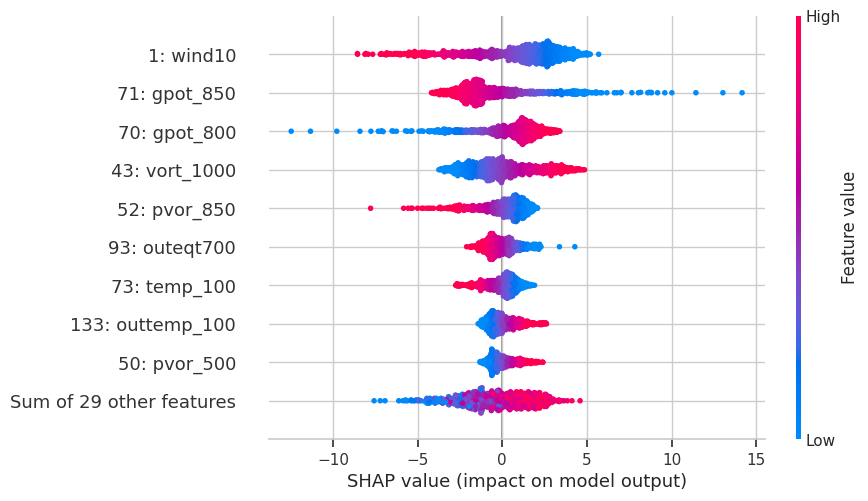

In [ ]:
# @title SHAP beeswarm plot with feature names and indices
import shap
import matplotlib.pyplot as plt

# Combine feature index and variable name for each predictor
feature_labels = [
    f"{i}: {name}"
    for i, name in zip(causal_indices, causal_feature_names)
]

# Add the custom labels to the SHAP Explanation object
shap_values_plot = shap.Explanation(
    values=shap_values.values,
    base_values=shap_values.base_values,
    data=X_val_shap,
    feature_names=feature_labels
)

# Plot the 10 most important features
shap.plots.beeswarm(
    shap_values_plot,
    max_display=10
)

plt.show()

### Interpreting the SHAP Summary Plot

- **`wind10`** ranks highest because it represents actual wind speed, which is closely related to the target `DELV24` (24-hour intensity change).
- **`gpot_850` and `gpot_800`** describe geopotential at different pressure levels, while **`vort_1000`, `pvor_850`, and `pvor_500`** represent atmospheric rotation and dynamical structure.
- The SHAP values show how each feature contributes to predictions, but **high importance does not establish causality**.

### Step 4: Interpret the SHAP summary plot

The SHAP summary plot combines feature importance and the distribution of feature contributions across the validation samples.

- **Vertical axis:** Features are ranked by their mean absolute SHAP values, with the most influential features appearing at the top.
- **Horizontal axis:** SHAP value. Positive values increase the model's prediction relative to its reference prediction; negative values decrease it.
- **Point colour:** The original feature value, from low (blue) to high (red).

Look for features with large contributions and examine whether high and low values tend to push predictions in different directions. Compare these patterns with your meteorological understanding, keeping in mind that SHAP explains the fitted model rather than establishing physical causality.

### Q7. What does SHAP tell us—and what does it not tell us?

Use the SHAP summary plot to identify features with large attribution magnitudes and describe how feature values relate to model output in this fitted linear model.

Then explain why SHAP importance is not equivalent to causal importance. SHAP values explain a model's predictions relative to a background distribution; they do not validate the causal-discovery assumptions or establish a physical mechanism.

Coding help: [SHAP documentation](https://shap.readthedocs.io/).


### Possible solution : Interpret the SHAP Plot

In the Figure above, we used the outputs after M-PC selects the 38 predictors using conditional independence tests and specified causal assumptions. The MLR model learns their statistical relationships with `DELV24`, and SHAP estimates each predictor's contribution to model predictions relative to a reference prediction.

Here, SHAP explains predictions for the validation data (`X_val_shap`), using the training data (`X_train_shap`) as the background reference. **SHAP explains the fitted model; it does not establish causal effects or repeat causal discovery.**

---
## Final Summary and Key Takeaways

You have reached the end of this tutorial! Let's briefly recap the key ideas and methods explored along the way.

- **Causal discovery with M-PC:** Investigated candidate causal relationships across multiple storm time series while preserving their individual temporal structures.

- **Meteorological knowledge and causal constraints:** Incorporated domain knowledge through link assumptions to guide data-driven causal discovery.

- **Causal feature selection for forecasting:** Used selected predictors in a multiple linear regression model and examined whether they contribute to predictive performance.

- **Model evaluation:** Considered the importance of validation and independent storm data when assessing the usefulness of causal feature selection.

- **Model interpretation with SHAP:** Explored how individual features contribute to the fitted model's predictions and how these contributions can be compared with meteorological expectations.

### Final takeaway

Causal discovery, domain knowledge, predictive evaluation, and model interpretation address different questions. Used together, they provide a framework for investigating potential causal relationships and their usefulness for atmospheric forecasting.

Remember that discovered relationships depend on the data and assumptions, SHAP explains the fitted model rather than establishing physical causality, and improved predictive performance must be demonstrated through appropriate evaluation.

Thank you for working through this tutorial!

### Bonus: Reflect on the Evidence and Explore Further

Before finishing, take a moment to connect the different stages of the tutorial.

In **4–6 sentences**, summarise your findings by considering:

1. **Causal discovery:** What does M-PC contribute to identifying candidate predictors of tropical cyclone intensity change?

Ans:

2. **Feature selection:** How does the selected feature subset compare with conventional statistical feature selection methods?

Ans:

3. **Forecasting performance:** Do the validation and unseen-storm results support a predictive benefit from causal feature selection?

Ans:

4. **Limitations:** What is one important limitation of the method or your evaluation?

Ans:

5. **Beyond tropical cyclones:** What other weather or climate applications could benefit from causal feature selection, and why?

Ans:

**Suggested structure:** Discovery method → feature selection comparison → forecasting evidence → limitation → potential applications.

Causal feature selection offers a complementary, physically informed approach to conventional statistical methods. Use the results from your run to assess its predictive value, and consider where this approach might be useful beyond tropical cyclone intensity forecasting—for example, in extreme rainfall prediction, heatwave forecasting, or understanding drivers of climate variability. Remember that the usefulness of a method depends on the scientific question, the available data, and the evidence supporting its results.

### Further coding help

- [NumPy user guide](https://numpy.org/doc/stable/user/)
- [pandas user guide](https://pandas.pydata.org/docs/user_guide/index.html)
- [Matplotlib tutorials](https://matplotlib.org/stable/tutorials/index.html)
- [scikit-learn model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [Tigramite](https://github.com/jakobrunge/tigramite)
- [SHAP](https://shap.readthedocs.io/)


---
## References

1. **Ganesh, S. S., F. I.-H. Tam, M. S. Gomez, M. McGraw, M. DeMaria, K. Musgrave, J. Runge, and T. Beucler**, 2026: *Multidata Causal Discovery for Statistical Hurricane Intensity Forecasting*. **Weather and Forecasting**, 41 (7), 1359–1375, [https://doi.org/10.1175/WAF-D-25-0208.1](https://doi.org/10.1175/WAF-D-25-0208.1).
2. **Ganesh, S. S., et al.**, 2026: *Supplementary Information (SI): Multidata Causal Discovery for Statistical Hurricane Intensity Forecasting*. **Weather and Forecasting**, [https://doi.org/10.1175/WAF-D-25-0208.s1](https://doi.org/10.1175/WAF-D-25-0208.s1).
3. **Runge, J., P. Nowack, M. Kretschmer, S. Flaxman, and D. Sejdinovic**, 2019: *Detecting and quantifying causal associations in large nonlinear time series datasets*. **Science Advances**, 5 (11), eaau4996, [https://doi.org/10.1126/sciadv.aau4996](https://doi.org/10.1126/sciadv.aau4996).
4. **DeMaria, M., and J. Kaplan**, 1994: *A Statistical Hurricane Intensity Prediction Scheme (SHIPS) for the Atlantic basin*. **Weather and Forecasting**, 9 (2), 209–220, [https://doi.org/10.1175/1520-0434(1994)009<0209:ASHIPS>2.0.CO;2](https://doi.org/10.1175/1520-0434(1994)009<0209:ASHIPS>2.0.CO;2).
5. **Razin, M. N., C. J. Slocum, J. A. Knaff, P. J. Brown, and M. M. Bell**, 2023: *Tropical Cyclone Precipitation, Infrared, Microwave, and Environmental Dataset (TC PRIMED)*. **Bulletin of the American Meteorological Society**, 104 (11), E1980–E1998, [https://doi.org/10.1175/BAMS-D-21-0052.1](https://doi.org/10.1175/BAMS-D-21-0052.1).